# Statistics on a List of Numbers — and the Algorithms Behind Them

*Python for Engineers: Case Studies from Calculator to Simulation* · Notebook 18 · Yanwei Wang

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/ktwyw/python-for-engineers-case-studies/blob/main/notebooks/18_Statistics_and_Complexity_Extended.ipynb)

*Python · statistics · algorithms · data analytics, in one notebook*

> 📚 **Want to go deeper?** This notebook is a gateway to the open-source **engstat** project:
> [github.com/ktwyw/engstat](https://github.com/ktwyw/engstat) — a validated engineering-statistics library in Python (control charts, process capability, designed experiments, measurement uncertainty, Weibull life analysis, and more), with a 19-notebook course and worked solutions to all 57 of its exercises. Everything here scales up there.

Engineers collect numbers all the time — sensor readings, test results, measurements. This notebook starts with the simplest possible container for numbers, a **Python list**, and asks four questions over and over:

1. **What** do we want to know about the data? → *statistics* (mean, median, spread, outliers…)
2. **How** does the computer compute it, step by step? → *algorithms*
3. **How much work** is that as the data grows? → *computational complexity* (Big-O)
4. **Can we do better**, and what does "better" cost? → *engineering trade-offs*

### How this notebook is organised

| Part | Sections | What you'll learn |
|---|---|---|
| **Foundations** | 0–2 | Just enough Python; the datasets; what Big-O means |
| **One statistic at a time** | 3–10 | Mean, median, mode, variance, min/max, sorting, percentiles, histograms — each with a hand-written algorithm, its complexity, and faster alternatives |
| **Measuring & packaging** | 11–13 | Timing experiments, memory, and bundling everything into a reusable `StatAnalyzer` class |
| **Mini project** | 14 | A small, realistic data-analytics task from raw readings to conclusions |
| **Wrap-up** | 15–18 | Summary table, exercises, where to go next (engstat on GitHub), glossary |

Every statistic follows the same four-step rhythm: **Define → Implement → Analyse → Compare**.

### How to use it

* Run cells **top to bottom** (`Runtime → Run all` in Colab, or `Shift+Enter` on each cell). Later cells depend on earlier ones.
* 🤔 **Predict first** boxes ask you to guess an output *before* running the cell. Guessing wrong is the fastest way to learn.
* 🧪 **Try it** cells are meant to be edited. Break things. Then fix them.
* ✅ **Checkpoint** questions are for discussion — there's no code to run.

Nothing is hidden behind a library until you have seen the hand-written version first.

<!-- pfe-study-guide -->
## Study guide

| | |
|---|---|
| **Status** | Optional · Extensions (a deeper version of notebook 04) |
| **Time** | about 80 min of reading |
| **Before this** | Notebook 04. |
| **Essential** | If you work through it: Sections 0–6, 8, 11 and 14. |
| **Optional on a first reading** | Sections 7, 9, 10, 12 and 13; the exercises and glossary are for reference. |
| **Next** | Any other extension. |

**You have understood this notebook if you can, without looking back:**

1. Explain why the textbook one-pass variance formula loses precision, and how Welford's update avoids it.
2. Compare bubble, insertion, merge and quick sort by measured time, and say which one you would never use and why.
3. Fit the slope of a log–log timing plot to estimate an algorithm's growth rate.
4. Package several statistics in a class, and explain the cost and benefit of sorting once in the constructor.
5. Turn raw readings with gaps and a suspicious value into a short, defensible conclusion (the Section 14 mini project).

**Not expected of you:** Every algorithm in every section; skim what you do not need.

*The comment on every code line is a reading aid. In your own programs, comment the reasons and the non-obvious steps.*

## 0. Setup and a 10-minute Python refresher

### 0.1 Imports

Everything we need is either in Python's standard library or preinstalled in Colab (NumPy, Matplotlib).

In [1]:
# Python's built-in random numbers (used for simulated data and random pivots).
import random
# time.perf_counter() is a high-resolution stopwatch.
import time
# Square roots, floor and ceiling.
import math
# System information: the Python version and object sizes in bytes.
import sys
# Counter is a dictionary specialised for counting.
from collections import Counter

# NumPy: fast arrays and vectorised statistics.
import numpy as np
# Matplotlib for plots.
import matplotlib.pyplot as plt
# The warnings module controls warning messages.
import warnings
# Hide deprecation warnings so the output stays readable.
warnings.filterwarnings("ignore", category=DeprecationWarning)

# Default figure size (width, height) in inches.
plt.rcParams["figure.figsize"] = (8, 4)
# Draw a light grid on every plot.
plt.rcParams["axes.grid"] = True
# Fix Python's random seed, so everyone gets the same numbers.
random.seed(42)
# Fix NumPy's legacy global seed too.
np.random.seed(42)
# Print the versions, so results can be compared across computers.
print("Python", sys.version.split()[0], "| NumPy", np.__version__)

Python 3.13.18 | NumPy 2.5.3


### 0.2 Python essentials used in this notebook

If you are comfortable with lists, loops, functions and f-strings, skim this and move on. Otherwise, run each cell and read the comments — every construct here is used later.

**Lists** hold an ordered sequence of values. Positions (indices) start at **0**.

In [2]:
readings = [4.2, 5.1, 3.9, 6.0, 5.5]        # a list of 5 floats

print(readings[0])          # first element → 4.2
print(readings[-1])         # last element  → 5.5   (negative index counts from the end)
print(readings[1:3])        # "slice": elements at index 1 and 2 (3 is excluded) → [5.1, 3.9]
print(len(readings))        # number of elements → 5

readings.append(4.8)        # add to the end (changes the list in place)
# Print the whole list: it now has six readings.
print(readings)

4.2
5.5
[5.1, 3.9]
5
[4.2, 5.1, 3.9, 6.0, 5.5, 4.8]


**`for` loops** visit each element in turn. **`if`** makes decisions. Indentation (4 spaces) is how Python knows what's inside the loop.

In [3]:
# Running total, starts at zero.
total = 0.0
# Counter for values above 5.
count_above_5 = 0

for x in readings:          # x takes each value in the list, one at a time
    total = total + x       # same as: total += x
    # Is this value above 5?
    if x > 5:
        # Count it.
        count_above_5 += 1

# Print the total.
print("total =", total)
# Print the count.
print("values above 5:", count_above_5)

total = 29.500000000000004
values above 5: 3


**Functions** package a computation so you can reuse it. `def` defines it, `return` hands back the result. The text between triple quotes is a *docstring* — a note explaining what the function does.

In [4]:
# Define a reusable function that computes the mean.
def average(numbers):
    '''Return the arithmetic mean of a non-empty list of numbers.'''
    # Running total.
    total = 0.0
    # Visit each number once.
    for x in numbers:
        # Add it.
        total += x
    # Divide by the count.
    return total / len(numbers)

# Use the function on our readings.
print(average(readings))
print(average([10, 20, 30]))      # works on any list of numbers

4.916666666666667
20.0


**f-strings** format output. Put `f` before the quote and expressions inside `{}`. `:.2f` means "2 decimal places".

**List comprehensions** build a new list from an old one in one line — a compact `for` loop.

In [5]:
# Store the mean in a variable.
avg = average(readings)
# f-string: {avg:.2f} prints avg with 2 decimals.
print(f"mean = {avg:.2f}, n = {len(readings)}")

squares = [x ** 2 for x in readings]                 # same as a loop that appends x**2 for every x
big_ones = [x for x in readings if x > 5]            # with a filter
# Print the list of squares.
print(squares)
# Print the values above 5.
print(big_ones)

mean = 4.92, n = 6
[17.64, 26.009999999999998, 15.209999999999999, 36.0, 30.25, 23.04]
[5.1, 6.0, 5.5]


**Dictionaries** map keys to values — think of a lookup table. Looking something up by key is (on average) instant, regardless of how big the dictionary is. This single fact will matter a lot in Section 5.

In [6]:
counts = {}                      # empty dictionary
# Visit each grade in the list.
for grade in ["A", "B", "A", "C", "A", "B"]:
    counts[grade] = counts.get(grade, 0) + 1     # .get(key, 0) returns 0 if the key isn't there yet
print(counts)                    # {'A': 3, 'B': 2, 'C': 1}
print(counts["A"])               # look up by key → 3

{'A': 3, 'B': 2, 'C': 1}
3


> ✅ **Checkpoint 0.** In your own words: what is the difference between `readings[2]` and `readings[2:3]`? What does `counts.get("D", 0)` return?

That's all the Python you need to read everything that follows. New constructs (classes, generators, NumPy arrays) are introduced where they first appear.

## 1. The data

We'll use **three** datasets throughout:

* `small` — 15 integers (odd count). Small enough to verify every result by hand on the board.
* `scores` — 8 integers (even count). Shows the "two middle values" case for the median, and has **two** modes.
* `big` — 1,000,000 floats, large enough that algorithmic choices actually matter for running time.

`small` deliberately contains a repeated value (so the mode is well defined) and one outlier (so mean ≠ median).

In [7]:
small = [12, 7, 3, 7, 25, 9, 7, 14, 3, 18, 11, 7, 5, 96, 10]   # 96 is an outlier, 7 repeats 4 times
# Show the small dataset and its length.
print("small  =", small, "| n =", len(small))

scores = [12, 15, 12, 18, 22, 15, 12, 30]                       # even length; 12 appears 3×
# Show the scores and their length.
print("scores =", scores, "| n =", len(scores))

# One million (underscores make long numbers readable).
N_BIG = 1_000_000
# One million normally distributed values with mean 50 and standard deviation 15.
big = [random.gauss(mu=50, sigma=15) for _ in range(N_BIG)]
# {len(big):,} prints with thousands separators; show the first five values rounded.
print(f"big: n = {len(big):,}, first five = {[round(x, 2) for x in big[:5]]}")

small  = [12, 7, 3, 7, 25, 9, 7, 14, 3, 18, 11, 7, 5, 96, 10] | n = 15
scores = [12, 15, 12, 18, 22, 15, 12, 30] | n = 8


big: n = 1,000,000, first five = [47.84, 47.41, 48.33, 60.53, 48.09]


### A timing helper

We'll time functions many times. `timeit_fn` runs a function `repeat` times and reports the **best** time (best-of-k is the standard way to reduce noise from the OS, garbage collector, etc.).

In [8]:
# Define a helper that runs a function several times and keeps the fastest time.
def timeit_fn(fn, *args, repeat=3, **kwargs):
    '''Return (result, best_seconds) of calling fn(*args, **kwargs) `repeat` times.'''
    # Best time so far (infinity, so the first run always beats it).
    best = float("inf")
    # Will hold the function's result.
    result = None
    # Repeat the measurement.
    for _ in range(repeat):
        # Start the stopwatch.
        t0 = time.perf_counter()
        # Call the function being timed.
        result = fn(*args, **kwargs)
        # Keep the shortest time (least disturbed by other programs).
        best = min(best, time.perf_counter() - t0)
    # Return the result and the best time.
    return result, best

# Define a helper that prints a label, a value and the time in ms in aligned columns.
def show(label, value, secs):
    # :<42 left-aligns in 42 characters; !s converts the value to a string first.
    print(f"{label:<42} = {value!s:<22}  [{secs*1000:9.3f} ms]")

## 2. Computational complexity in 10 minutes

### 2.1 Why count operations instead of seconds?

Seconds depend on the computer, the language, what else is running. The **number of elementary operations** — additions, comparisons, assignments, array lookups — depends only on the algorithm and the input size $n$. So that's what we count.

Let's count by hand on a tiny example:

In [9]:
# Define a function that sums a list while counting its operations.
def count_ops_sum(data):
    '''Sum a list AND count the elementary operations performed.'''
    # Operation counter.
    ops = 0
    total = 0;           ops += 1          # one assignment
    for x in data:                         # the loop runs len(data) times…
        total += x;      ops += 1          # …each time: one addition
    # Return both the sum and the count.
    return total, ops

# Try lists of 1, 10, 100 and 1000 items.
for n in [1, 10, 100, 1000]:
    # Sum 0, 1, ..., n-1 and count the operations.
    total, ops = count_ops_sum(list(range(n)))
    # The count grows in proportion to n: O(n).
    print(f"n = {n:5d} → {ops:5d} operations")

n =     1 →     2 operations
n =    10 →    11 operations
n =   100 →   101 operations
n =  1000 →  1001 operations


The operation count is $n + 1$. The "+1" quickly becomes irrelevant — at $n = 1000$ it's 0.1% of the work. **Big-O notation** keeps only the dominant term and drops constants: we say the sum is $O(n)$, "order $n$", "linear".

### 2.2 The common complexity classes

**Big-O notation** describes how the *number of elementary operations* grows with input size $n$, ignoring constants and lower-order terms.

| Notation | Name | Intuition: if $n$ doubles, work… | Example |
|---|---|---|---|
| $O(1)$ | constant | stays the same | `lst[0]`, `len(lst)` |
| $O(\log n)$ | logarithmic | grows by +1 step | binary search |
| $O(n)$ | linear | doubles | sum of a list |
| $O(n \log n)$ | linearithmic | slightly more than doubles | good sorting |
| $O(n^2)$ | quadratic | quadruples | comparing every pair |
| $O(2^n)$ | exponential | squares (!) | brute-force subsets |

Two kinds of complexity matter:

* **Time complexity** — how many operations.
* **Space complexity** — how much *extra* memory beyond the input.

And three cases: **best**, **average**, and **worst**. Usually we care about worst case, but for some algorithms (quicksort, quickselect) the *average* case is what makes them practical.

### 2.3 Seeing it: how fast does the work grow?

First on ordinary axes, for $n$ up to 100. Watch $O(n^2)$ shoot off the top of the chart.

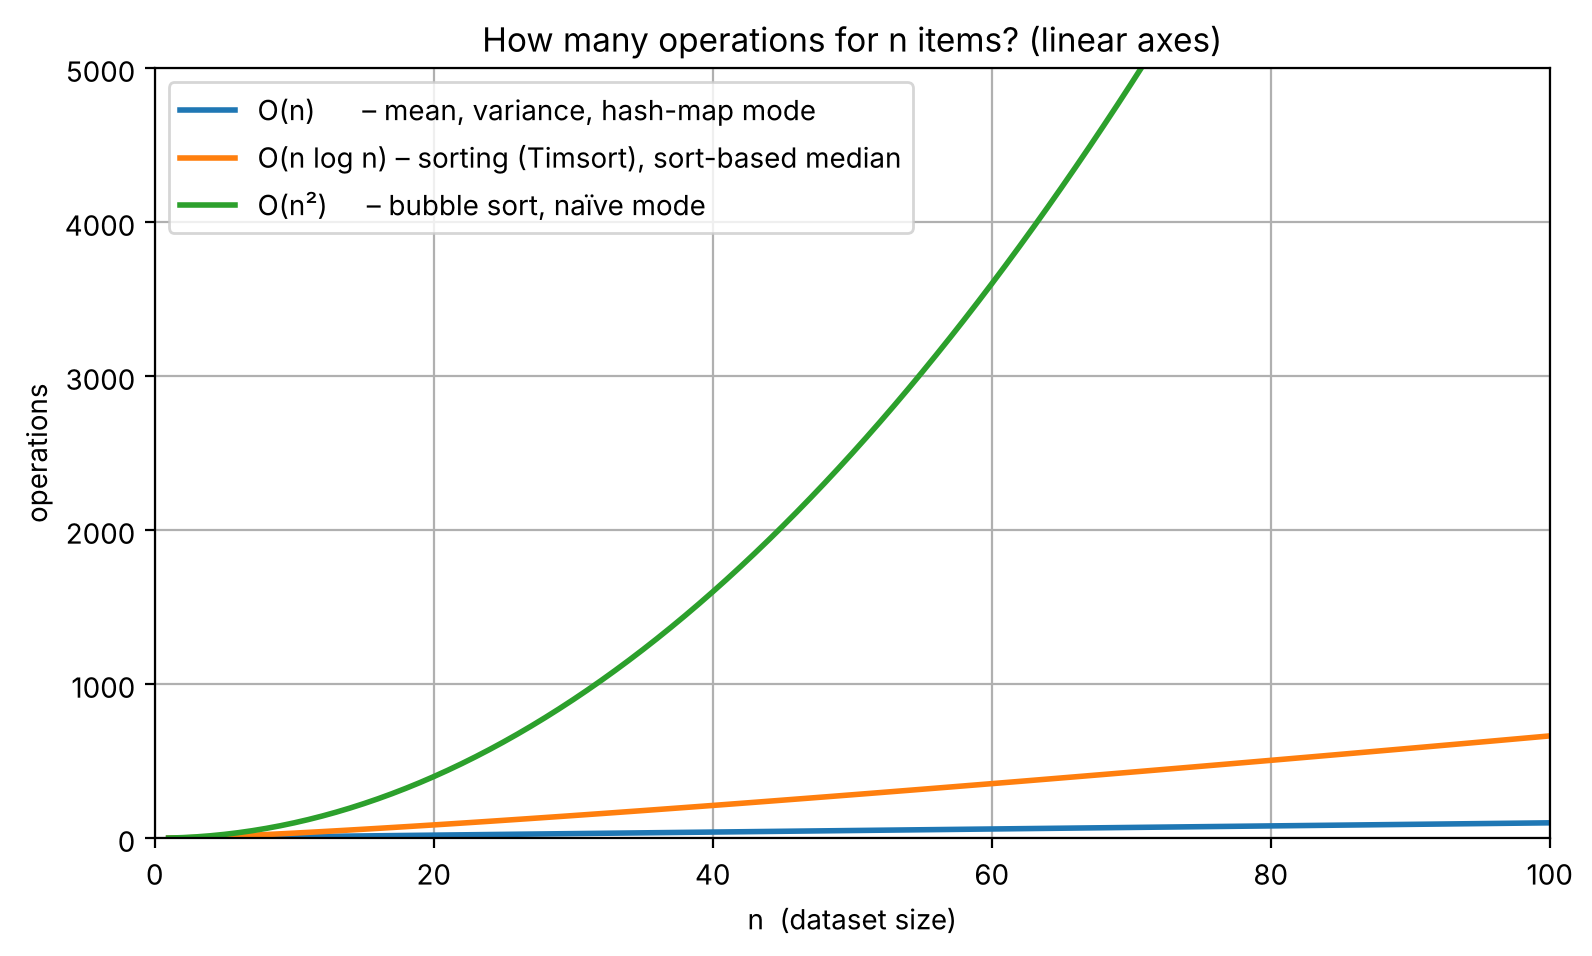

In [10]:
# 100 values of n from 1 to 100.
n = np.linspace(1, 100, 100)

# New figure.
plt.figure(figsize=(9, 5))
# A straight line: O(n).
plt.plot(n, n,               label="O(n)      – mean, variance, hash-map mode", linewidth=2)
# Slightly faster than linear: O(n log n).
plt.plot(n, n * np.log2(n),  label="O(n log n) – sorting (Timsort), sort-based median", linewidth=2)
# A parabola: O(n²).
plt.plot(n, n ** 2,          label="O(n²)     – bubble sort, naïve mode", linewidth=2)
# Fix the axis ranges.
plt.ylim(0, 5000); plt.xlim(0, 100)
# Title.
plt.title("How many operations for n items? (linear axes)")
# Axis labels.
plt.xlabel("n  (dataset size)"); plt.ylabel("operations")
# Legend, then display.
plt.legend(); plt.show()

> 🤔 **Predict first:** at $n = 100$, roughly how many operations does each curve need? (Answers: 100, ~660, 10,000.) Now imagine $n = 1{,}000{,}000$.

The same curves on **log–log axes** turn into straight lines, which is much easier to read when $n$ spans several orders of magnitude:

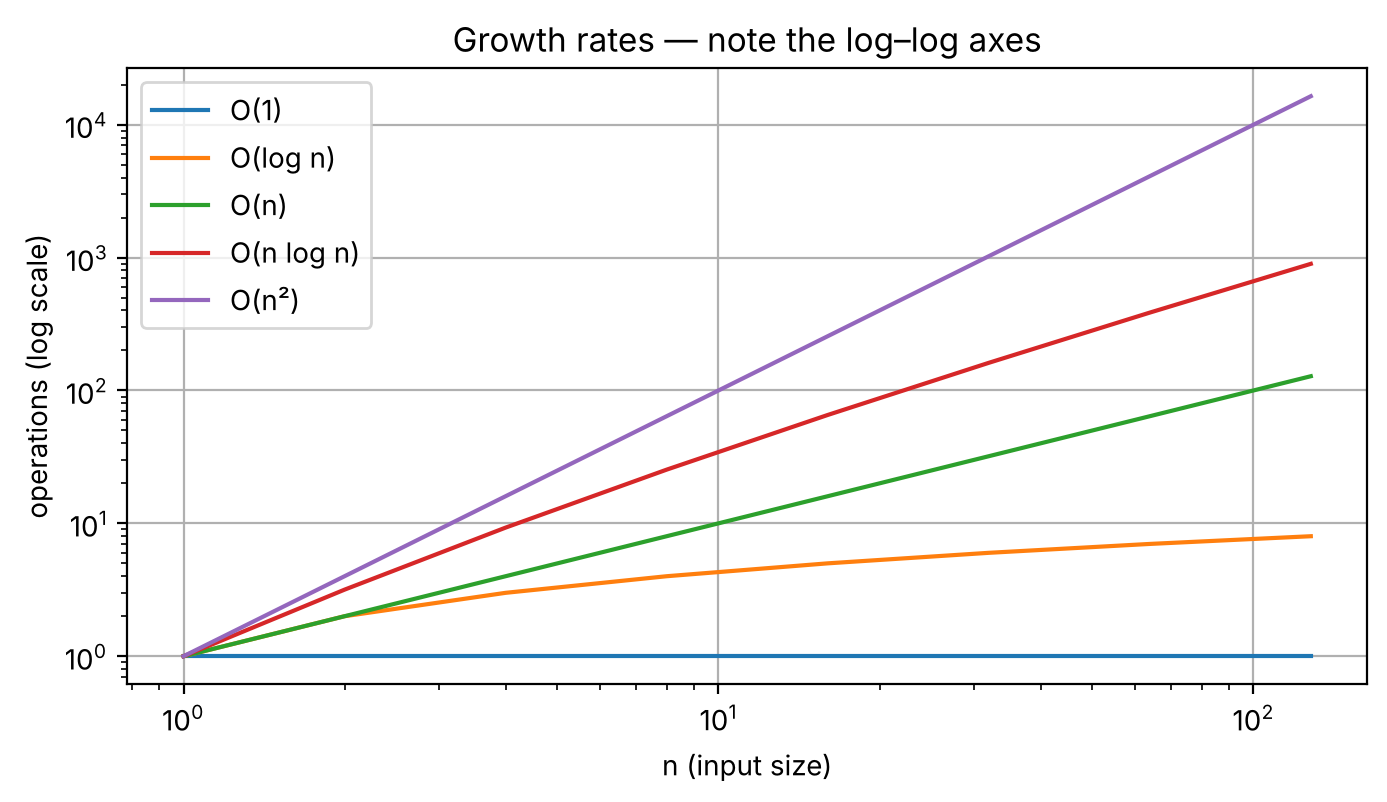

In [11]:
# Powers of 2 from 1 to 128.
ns = np.array([1, 2, 4, 8, 16, 32, 64, 128])
# New figure.
plt.figure()
# Constant cost.
plt.plot(ns, np.ones_like(ns), label="O(1)")
# Logarithmic cost (+1 so it starts at 1).
plt.plot(ns, np.log2(ns) + 1, label="O(log n)")
# Linear cost.
plt.plot(ns, ns, label="O(n)")
# n log n cost (n + 1 inside the log keeps the curve above zero at n = 1).
plt.plot(ns, ns * np.log2(ns + 1), label="O(n log n)")
# Quadratic cost.
plt.plot(ns, ns ** 2, label="O(n²)")
# Log scales on both axes turn power laws into straight lines.
plt.yscale("log"); plt.xscale("log")
# Axis labels.
plt.xlabel("n (input size)"); plt.ylabel("operations (log scale)")
# Title.
plt.title("Growth rates — note the log–log axes")
# Legend, then display.
plt.legend(); plt.show()

> **Reading the plot:** on log–log axes a polynomial $n^k$ is a straight line with slope $k$. We'll use this trick in Section 11 to *measure* the complexity of our own code.

## 3. Mean (arithmetic average)

$$\bar{x} = \frac{1}{n}\sum_{i=1}^{n} x_i$$

### 3.1 Hand-written: one pass

In [12]:
# Define the mean computed with an explicit loop.
def mean_loop(data):
    # Running total.
    total = 0.0
    for x in data:          # n iterations
        total += x          # 1 addition each
    return total / len(data)   # 1 division

# Test on the small dataset.
print("mean(small) =", mean_loop(small))

mean(small) = 15.6


### Analysis

* The loop body runs exactly $n$ times, each doing $O(1)$ work → **Time: $O(n)$**.
* We store only `total` → **Space: $O(1)$** extra.

Can we do better than $O(n)$? **No.** Every element can change the answer, so any correct algorithm must at least *look at* every element. $\Omega(n)$ is a **lower bound**, so $O(n)$ is optimal.

### 3.2 Alternatives — same complexity, different constants

Big-O hides constant factors, but constants matter in practice. Compare three $O(n)$ implementations:

In [13]:
# Define the mean using the built-in sum().
def mean_builtin(data):
    return sum(data) / len(data)          # sum() is a C loop

# Define the mean using NumPy.
def mean_numpy(data):
    return np.mean(data)                   # vectorised C, SIMD-friendly

big_np = np.array(big)                     # convert once (itself O(n))

# Three versions to compare, each with the input it expects.
for label, fn, arg in [("mean_loop (pure Python)", mean_loop, big),
                       ("mean_builtin (sum/len)", mean_builtin, big),
                       ("mean_numpy (on np.array)", mean_numpy, big_np)]:
    # Time it (best of 3).
    v, t = timeit_fn(fn, arg)
    # Print the result and the time.
    show(label, round(v, 6), t)

mean_loop (pure Python)                    = 49.976787               [   16.939 ms]
mean_builtin (sum/len)                     = 49.976787               [    5.985 ms]
mean_numpy (on np.array)                   = 49.976787               [    0.423 ms]


All three are $O(n)$ — doubling the list doubles each one's time — but the constant factor differs by ~50–100×.
**Lesson:** Big-O tells you how an algorithm *scales*; the implementation tells you how *fast* it is.

### 3.3 Streaming (online) mean — when the data doesn't fit in memory

Suppose values arrive one at a time (sensor readings, a log file bigger than RAM). We can update the mean incrementally:

$$\bar{x}_k = \bar{x}_{k-1} + \frac{x_k - \bar{x}_{k-1}}{k}$$

Still $O(n)$ total time, $O(1)$ space — but now we never need the whole list at once.

In [14]:
# Define a generator that yields the mean after each new value.
def running_mean(stream):
    # Running mean, starts at zero.
    mean = 0.0
    # k counts the values: 1, 2, 3, ...
    for k, x in enumerate(stream, start=1):
        # Update the mean without storing the earlier values.
        mean += (x - mean) / k
        # Hand back the current mean and pause until the next value is requested.
        yield mean

# Ask the generator for one running mean at a time.
for k, m in enumerate(running_mean(small), 1):
    # Print it.
    print(f"after {k:2d} values: mean = {m:7.3f}")

after  1 values: mean =  12.000
after  2 values: mean =   9.500
after  3 values: mean =   7.333
after  4 values: mean =   7.250
after  5 values: mean =  10.800
after  6 values: mean =  10.500
after  7 values: mean =  10.000
after  8 values: mean =  10.500
after  9 values: mean =   9.667
after 10 values: mean =  10.500
after 11 values: mean =  10.545
after 12 values: mean =  10.250
after 13 values: mean =   9.846
after 14 values: mean =  16.000
after 15 values: mean =  15.600


## 4. Median — where the algorithm choice really matters

The median is the middle value when the data is sorted (or the average of the two middle values if $n$ is even). It is **robust to outliers**: our `96` barely moves it.

### 4.1 Approach A: sort, then pick the middle

In [15]:
# Define the median by sorting.
def median_sort(data):
    s = sorted(data)                 # O(n log n)  — Python's Timsort
    # Number of values.
    n = len(s)
    # Middle index (integer division).
    mid = n // 2
    # Odd number of values?
    if n % 2 == 1:
        # The single middle value.
        return s[mid]
    # Even number: the average of the two middle values.
    return (s[mid - 1] + s[mid]) / 2

# Show the sorted data.
print("sorted(small) =", sorted(small))
# Compare the median with the mean: the outlier 96 pulls the mean up.
print("median(small) =", median_sort(small), "   vs mean =", round(mean_loop(small), 2))

sorted(small) = [3, 3, 5, 7, 7, 7, 7, 9, 10, 11, 12, 14, 18, 25, 96]
median(small) = 9    vs mean = 15.6


> 🤔 **Predict first:** `scores` has 8 elements — an *even* number. After sorting, which two values are "in the middle", and what is their average? Then run the trace below.

In [16]:
# Sort the scores.
s = sorted(scores)
# n = 8.
n = len(s)
# Middle index 4.
mid = n // 2
# Show the sorted list.
print("sorted(scores) =", s)
# Show n and the middle index.
print("n =", n, "→ mid index =", mid)
# For even n the two middle values sit at mid-1 and mid.
print(f"two middle values: s[{mid-1}] = {s[mid-1]} and s[{mid}] = {s[mid]}")
# Their average is the median.
print("median =", median_sort(scores))
# The mean, for comparison.
print("mean   =", round(mean_loop(scores), 3), "  ← pulled up by the 30")

sorted(scores) = [12, 12, 12, 15, 15, 18, 22, 30]
n = 8 → mid index = 4
two middle values: s[3] = 15 and s[4] = 15
median = 15.0
mean   = 17.0   ← pulled up by the 30


**Time: $O(n \log n)$** — entirely dominated by the sort. **Space: $O(n)$** for the sorted copy.

But wait — sorting does *far more* than we need. We don't care about the order of the other $n-1$ elements; we only want the $k$-th smallest one. This is the **selection problem**.

### 4.2 Approach B: Quickselect — $O(n)$ on average

Quickselect (Hoare, 1961) borrows quicksort's partition step but recurses into **only one side**:

1. Pick a pivot.
2. Partition into `< pivot`, `== pivot`, `> pivot`.
3. The $k$-th smallest is in exactly one of those groups — recurse into just that one.

Because we discard a constant fraction each time, the expected work is $n + n/2 + n/4 + \dots = 2n = O(n)$.

In [17]:
# Define quickselect: find the k-th smallest value without sorting everything.
def quickselect(data, k):
    '''Return the k-th smallest element (0-indexed) in expected O(n) time.'''
    # Only one value left?
    if len(data) == 1:
        # It must be the answer.
        return data[0]
    pivot = random.choice(data)                       # random pivot → good average case
    # Values smaller than the pivot.
    lows  = [x for x in data if x < pivot]
    # Values larger than the pivot.
    highs = [x for x in data if x > pivot]
    pivots = len(data) - len(lows) - len(highs)       # count of elements == pivot
    # Is the answer among the smaller values?
    if k < len(lows):
        # Search only there.
        return quickselect(lows, k)
    # Is it one of the values equal to the pivot?
    elif k < len(lows) + pivots:
        # Then the pivot is the answer.
        return pivot
    # Otherwise it is among the larger values ...
    else:
        # ... so search there, shifting k past the smaller and equal values.
        return quickselect(highs, k - len(lows) - pivots)

# Define the median using quickselect.
def median_quickselect(data):
    # Number of values.
    n = len(data)
    # Odd n?
    if n % 2 == 1:
        # The middle order statistic.
        return quickselect(data, n // 2)
    # Even n: average the two middle order statistics.
    return (quickselect(data, n // 2 - 1) + quickselect(data, n // 2)) / 2

# Median of the small dataset.
print("median via quickselect =", median_quickselect(small))
# Check it against the sorting method.
assert median_quickselect(small) == median_sort(small)

median via quickselect = 9


### Worst case: $O(n^2)$

If the pivot is always the smallest element, each step only removes one element: $n + (n-1) + (n-2) + \dots = O(n^2)$.
A **random pivot** makes this astronomically unlikely. (The *median-of-medians* algorithm guarantees $O(n)$ worst case but with a large constant; NumPy's `np.partition` uses **introselect**, which starts as quickselect and falls back to a guaranteed-linear method if it detects bad luck.)

### 4.3 Race: sort vs. quickselect vs. NumPy

In [18]:
# Define the median using NumPy.
def median_numpy(arr):
    return np.median(arr)          # uses np.partition (introselect) → O(n) average

# Three median methods, each with the input it expects.
for label, fn, arg in [("median_sort  O(n log n)", median_sort, big),
                       ("median_quickselect  O(n) avg", median_quickselect, big),
                       ("median_numpy  O(n) avg, C", median_numpy, big_np)]:
    # Time it.
    v, t = timeit_fn(fn, arg)
    # Print the result and the time.
    show(label, round(float(v), 4), t)

median_sort  O(n log n)                    = 49.9584                 [  243.590 ms]


median_quickselect  O(n) avg               = 49.9584                 [  338.303 ms]
median_numpy  O(n) avg, C                  = 49.9584                 [   12.920 ms]


> 🧪 **Try it:** our pure-Python `quickselect` builds new lists at every level (so it uses $O(n)$ extra space and pays Python's per-element overhead). It's "only" $O(n)$ but may not beat `sorted()` — which is written in C — until $n$ is very large. Increase `N_BIG` or re-run to see when the asymptotic advantage overtakes the constant-factor disadvantage. **This tension between asymptotics and constants is the single most important practical lesson of the notebook.**

## 5. Mode — three algorithms, three complexities

The mode is the most frequent value. This is the clearest example of how **choosing a better data structure changes the complexity class**.

### 5.1 Naïve: for each element, count how many times it appears — $O(n^2)$

In [19]:
# Define the naive mode: count every value by scanning the whole list.
def mode_naive(data):
    # Best value and its count so far.
    best_val, best_count = None, 0
    for x in data:                       # n
        # Count for this candidate.
        c = 0
        for y in data:                   #   × n
            # Equal to the candidate?
            if y == x:
                # Count it.
                c += 1
        # More frequent than the best so far?
        if c > best_count:
            # Remember it.
            best_val, best_count = x, c
    # Return the mode and its count.
    return best_val, best_count

# Test on the small dataset.
print("mode_naive(small) =", mode_naive(small))

mode_naive(small) = (7, 4)


### 5.2 Sort, then scan runs — $O(n \log n)$

After sorting, equal values are adjacent, so one linear scan finds the longest run.

In [20]:
# Define the mode by sorting: equal values end up next to each other.
def mode_sorted(data):
    s = sorted(data)                     # O(n log n)
    # Best value and its count so far.
    best_val, best_count = s[0], 1
    # The value in the current run of equal values, and the run's length.
    cur_val, cur_count = s[0], 1
    for x in s[1:]:                      # O(n)
        # Same as the current run?
        if x == cur_val:
            # The run gets longer.
            cur_count += 1
        # A new value starts ...
        else:
            # ... a new run of length 1.
            cur_val, cur_count = x, 1
        # Is the current run the longest so far?
        if cur_count > best_count:
            # Remember it.
            best_val, best_count = cur_val, cur_count
    # Return the mode and its count.
    return best_val, best_count

# Test on the small dataset.
print("mode_sorted(small) =", mode_sorted(small))

mode_sorted(small) = (7, 4)


### 5.3 Hash map (dictionary) counting — $O(n)$ average

A Python `dict` gives $O(1)$ *average* insert/lookup (hash table). One pass to count, one pass over the distinct keys to find the max.

**Space: $O(d)$** where $d$ = number of distinct values — this is the price we pay for speed.

In [21]:
# Define the mode using a dictionary of counts.
def mode_dict(data):
    # Empty dictionary: value -> count.
    counts = {}
    for x in data:                       # O(n), each op O(1) average
        # get(x, 0) returns 0 the first time x is seen; then add 1.
        counts[x] = counts.get(x, 0) + 1
    best_val = max(counts, key=counts.get)   # O(d), d = distinct values
    # Return the mode and its count.
    return best_val, counts[best_val]

def mode_counter(data):                  # same algorithm, stdlib implementation
    # most_common(1) returns a list with the single (value, count) pair; [0] takes it.
    val, cnt = Counter(data).most_common(1)[0]
    # Return the mode and its count.
    return val, cnt

# Dictionary version.
print("mode_dict(small)    =", mode_dict(small))
# Counter version: the same answer.
print("mode_counter(small) =", mode_counter(small))

mode_dict(small)    = (7, 4)
mode_counter(small) = (7, 4)


### What if two values tie? Multimodal data

All three versions above return *one* mode. But data can be **bimodal** (two most-frequent values) or have no meaningful mode at all (every value appears once). An honest implementation returns **all** values that reach the maximum count. Still $O(n)$: one pass to count, one pass over the distinct values to collect the winners.

In [22]:
# Define a function that returns every tied mode.
def modes_all(data):
    '''Return (list_of_modes, count). Handles ties.'''
    counts = Counter(data)                            # O(n)
    max_count = max(counts.values())                  # O(d)
    return [v for v, c in counts.items() if c == max_count], max_count   # O(d)

# Only 7 is a mode.
print("small  →", modes_all(small))
# Only 12 is a mode.
print("scores →", modes_all(scores))
# A tie: both 1 and 2.
print("ties   →", modes_all([1, 1, 2, 2, 3]))
# Every value occurs once, so every value is a mode.
print("no repeats →", modes_all([5, 6, 7]), "  (every value is 'the mode' — not informative)")

small  → ([7], 4)
scores → ([12], 3)
ties   → ([1, 2], 2)
no repeats → ([5, 6, 7], 1)   (every value is 'the mode' — not informative)


> ✅ **Checkpoint 5.** `Counter(data)` is a dictionary under the hood. Why does a dictionary make counting $O(n)$ while the naïve nested loop is $O(n^2)$? What does the dictionary *cost* us in exchange?

### 5.4 Race on 10,000 integers

(`mode_naive` already needs $10^8$ comparisons here — a few seconds. On the million-element list it would need $10^{12}$ and take **hours**. That's what $O(n^2)$ *means*.)

In [23]:
ints = [random.randint(1, 500) for _ in range(10_000)]   # many repeats → meaningful mode

# Four mode algorithms to compare.
for label, fn in [("mode_naive   O(n²)", mode_naive),
                  ("mode_sorted  O(n log n)", mode_sorted),
                  ("mode_dict    O(n)", mode_dict),
                  ("mode_counter O(n)", mode_counter)]:
    # Time each one (only once for the slow naive version).
    v, t = timeit_fn(fn, ints, repeat=1 if fn is mode_naive else 3)
    # Print the result and the time.
    show(label, v, t)

mode_naive   O(n²)                         = (478, 34)               [ 2361.766 ms]
mode_sorted  O(n log n)                    = (275, 34)               [    1.682 ms]
mode_dict    O(n)                          = (478, 34)               [    0.561 ms]
mode_counter O(n)                          = (478, 34)               [    0.385 ms]


> **Discussion question:** the dict version wins *in time*, but what about memory if the values are 1,000,000 distinct floats? When might `mode_sorted` be the better engineering choice?

> **Why do the mode values differ above?** In `ints`, several values tie for the highest count. `mode_sorted` reports the *smallest* tied value, whereas the dictionary versions report the tied value *seen first*. Both answers are correct for a single-mode function; `modes_all` from Section 5 returns every tied value.

## 6. Variance & standard deviation — where *numerical* stability joins the story

$$\sigma^2 = \frac{1}{n}\sum_{i=1}^{n}(x_i - \bar{x})^2, \qquad \sigma = \sqrt{\sigma^2}$$

(Use $n-1$ instead of $n$ for the *sample* variance; we'll parameterise this with `ddof`.)

### 6.1 Two-pass algorithm — $O(n)$, two sweeps

In [24]:
# Define the two-pass variance: first the mean, then the squared deviations.
def variance_two_pass(data, ddof=0):
    # Number of values.
    n = len(data)
    mean = sum(data) / n                               # pass 1: O(n)
    ss = sum((x - mean) ** 2 for x in data)            # pass 2: O(n)
    # ddof=0 divides by n (population); ddof=1 by n - 1 (sample).
    return ss / (n - ddof)

# Variance of the small dataset.
v = variance_two_pass(small)
# The standard deviation is its square root.
print(f"variance(small) = {v:.3f}, std = {math.sqrt(v):.3f}")

variance(small) = 493.040, std = 22.205


### 6.2 "Textbook" one-pass formula — $O(n)$, one sweep, **but dangerous**

Algebra says $\sigma^2 = \frac{1}{n}\sum x_i^2 - \bar{x}^2$, so we could compute $\sum x$ and $\sum x^2$ in a single loop.

Same Big-O. Fewer passes. So why not? **Catastrophic cancellation**: if values are large but their spread is small, $\sum x^2 / n$ and $\bar{x}^2$ are two huge, nearly equal numbers, and subtracting them in floating point destroys the precision.

In [25]:
# Define the one-pass shortcut formula: E[x²] - (E[x])².
def variance_naive_one_pass(data, ddof=0):
    # Number of values.
    n = len(data)
    # Running sum and running sum of squares.
    s = s2 = 0.0
    # One pass over the data.
    for x in data:
        # Add x.
        s += x
        # Add x².
        s2 += x * x
    # Subtracting two huge, nearly equal numbers loses precision.
    return (s2 - s * s / n) / (n - ddof)

# Small spread around a huge offset: true variance is 2/3 ≈ 0.6667
shifted = [1e9 + 1, 1e9 + 2, 1e9 + 3]
# The two-pass result is correct.
print("two-pass      :", variance_two_pass(shifted))
# The one-pass shortcut gives a wrong answer.
print("naive one-pass:", variance_naive_one_pass(shifted), "  ← precision lost")

two-pass      : 0.6666666666666666
naive one-pass: 0.0   ← precision lost


### 6.3 Welford's online algorithm — one pass, $O(1)$ space, numerically stable

Welford (1962) updates the mean and the sum of squared deviations incrementally, avoiding the big-minus-big subtraction:

$$M_k = M_{k-1} + \frac{x_k - M_{k-1}}{k}, \qquad S_k = S_{k-1} + (x_k - M_{k-1})(x_k - M_k)$$

This is the algorithm used in production streaming systems.

In [26]:
# Define Welford's one-pass, numerically stable variance.
def variance_welford(data, ddof=0):
    # Running mean.
    mean = 0.0
    m2 = 0.0            # running sum of squared deviations
    # k counts the values: 1, 2, 3, ...
    for k, x in enumerate(data, start=1):
        # Deviation from the old mean.
        delta = x - mean
        # Update the mean.
        mean += delta / k
        # Update the sum of squares using the old and new deviations.
        m2 += delta * (x - mean)
    # Divide by n (or n - 1 with ddof=1).
    return m2 / (len(data) - ddof)

# Welford is correct, even on the shifted data.
print("welford       :", variance_welford(shifted))

# All three agree on well-behaved data, and NumPy agrees too
print(f"\nbig: two-pass={variance_two_pass(big):.5f}  welford={variance_welford(big):.5f}  numpy={np.var(big_np):.5f}")

welford       : 0.6666666666666666



big: two-pass=224.86535  welford=224.86535  numpy=224.86535


| Algorithm | Time | Space | Passes | Stable? |
|---|---|---|---|---|
| Two-pass | $O(n)$ | $O(1)$ | 2 | ✅ |
| Naïve one-pass | $O(n)$ | $O(1)$ | 1 | ❌ |
| Welford | $O(n)$ | $O(1)$ | 1 | ✅ |

**Lesson:** identical Big-O does not mean identical algorithms. Correctness under floating-point arithmetic is a separate axis of quality.

## 7. Minimum, maximum and range — counting comparisons precisely

Finding the min is $O(n)$ with $n-1$ comparisons. Finding min **and** max separately costs $2n-2$ comparisons. Can we do both in fewer?

Yes: process elements **in pairs**. Compare the pair (1 comparison), then compare the smaller to the running min and the larger to the running max (2 comparisons). That's 3 comparisons per 2 elements → about $1.5n$ instead of $2n$. Same $O(n)$, 25% fewer comparisons — a classic exam question.

In [27]:
# Define min/max with two comparisons per value.
def minmax_naive(data):
    # Comparison counter.
    comparisons = 0
    # Start with the first value as both minimum and maximum.
    lo = hi = data[0]
    # Visit every remaining value.
    for x in data[1:]:
        # Two comparisons follow.
        comparisons += 2
        # New minimum?
        if x < lo: lo = x
        # New maximum?
        if x > hi: hi = x
    # Return the results and the comparison count.
    return lo, hi, comparisons

# Define min/max that compares values in pairs: about 3 comparisons per 2 values.
def minmax_pairs(data):
    # Comparison counter.
    comparisons = 0
    # Number of values.
    n = len(data)
    if n % 2:                       # odd: seed with first element
        # Start with the first value; the loop then begins at index 1.
        lo = hi = data[0]; start = 1
    else:                           # even: seed with first pair
        # One comparison to order the first pair.
        comparisons += 1
        # Start with the first pair's smaller and larger values; the loop then begins at index 2.
        lo, hi = (data[0], data[1]) if data[0] < data[1] else (data[1], data[0]); start = 2
    # Step through the rest two at a time.
    for i in range(start, n - 1, 2):
        # The next pair.
        a, b = data[i], data[i + 1]
        # One comparison to order the pair ...
        comparisons += 1
        # ... smaller first ...
        if a < b: small_, large_ = a, b
        # ... or swapped.
        else:     small_, large_ = b, a
        # ... then two more comparisons:
        comparisons += 2
        # the smaller one against the minimum ...
        if small_ < lo: lo = small_
        # ... and the larger one against the maximum.
        if large_ > hi: hi = large_
    # Return the results and the comparison count.
    return lo, hi, comparisons

# Try both functions.
for fn in (minmax_naive, minmax_pairs):
    # Unpack the results.
    lo, hi, c = fn(small)
    # fn.__name__ is the function's name as a string.
    print(f"{fn.__name__:<13} min={lo:3d} max={hi:3d} range={hi-lo:3d}  comparisons={c}")

# Run both on the big data (two statements on one line, separated by ;).
lo, hi, c1 = minmax_naive(big); _, _, c2 = minmax_pairs(big)
# The pair method needs about 75% as many comparisons.
print(f"\nbig: naive {c1:,} comparisons vs pairs {c2:,}  (ratio {c2/c1:.2f})")

minmax_naive  min=  3 max= 96 range= 93  comparisons=28
minmax_pairs  min=  3 max= 96 range= 93  comparisons=21



big: naive 1,999,998 comparisons vs pairs 1,499,998  (ratio 0.75)


## 8. Sorting — the workhorse behind median, percentiles and more

Many statistics reduce to "sort first". So the complexity of sorting sets a ceiling on everything built on it. Let's implement three classic algorithms and watch their complexity classes separate in real time.

### 8.1 Bubble sort — $O(n^2)$, the one you should never use

In [28]:
# Define bubble sort, which returns a sorted copy.
def bubble_sort(data):
    # Copy, so the caller's list is not changed.
    a = list(data)
    # Number of values.
    n = len(a)
    for i in range(n):                        # n passes
        # Track whether this pass changed anything.
        swapped = False
        for j in range(0, n - i - 1):         #   each up to n comparisons
            # Adjacent pair out of order?
            if a[j] > a[j + 1]:
                # Swap them.
                a[j], a[j + 1] = a[j + 1], a[j]
                # Note that something changed.
                swapped = True
        if not swapped:                       # early exit: best case O(n) on sorted input
            # Stop early: no swaps means the list is sorted.
            break
    # Return the sorted copy.
    return a

# Test on the small dataset.
print(bubble_sort(small))

[3, 3, 5, 7, 7, 7, 7, 9, 10, 11, 12, 14, 18, 25, 96]


### 8.2 Insertion sort — $O(n^2)$ worst, $O(n)$ best, great for tiny or nearly-sorted inputs

Build the sorted prefix one element at a time, shifting larger elements right. Python's Timsort actually uses insertion sort for small runs because its constant factor is excellent.

In [29]:
# Define insertion sort, which returns a sorted copy.
def insertion_sort(data):
    # Copy the input.
    a = list(data)
    # a[0:i] is already sorted; insert a[i] into it.
    for i in range(1, len(a)):
        # The value to insert.
        key = a[i]
        # Start comparing with the element just to its left.
        j = i - 1
        while j >= 0 and a[j] > key:          # shifts: up to i per element → n²/2 worst
            # Shift the larger neighbour one place right.
            a[j + 1] = a[j]
            # Move one place further left.
            j -= 1
        # Drop the key into the gap.
        a[j + 1] = key
    # Return the sorted copy.
    return a

# Test on the small dataset.
print(insertion_sort(small))

[3, 3, 5, 7, 7, 7, 7, 9, 10, 11, 12, 14, 18, 25, 96]


### 8.3 Merge sort — $O(n \log n)$ guaranteed, $O(n)$ extra space

**Divide and conquer:** split in half, sort each half recursively, merge the two sorted halves in linear time.

Recurrence: $T(n) = 2\,T(n/2) + O(n)$ → by the Master Theorem, $T(n) = O(n \log n)$.
Intuition: $\log_2 n$ levels of recursion, each doing $O(n)$ merging work.

In [30]:
# Define merge sort: split, sort each half, merge.
def merge_sort(data):
    # Base case: 0 or 1 values are already sorted.
    if len(data) <= 1:
        # Return a copy.
        return list(data)
    # Split point.
    mid = len(data) // 2
    left  = merge_sort(data[:mid])            # T(n/2)
    right = merge_sort(data[mid:])            # T(n/2)
    return merge(left, right)                 # O(n)

# Define merge: combine two sorted lists into one sorted list.
def merge(left, right):
    # The merged output.
    out = []
    # Read positions in left and right.
    i = j = 0
    # While both lists still have values ...
    while i < len(left) and j < len(right):
        # ... take the smaller front value ...
        if left[i] <= right[j]:
            # ... from the left list (two statements on one line) ...
            out.append(left[i]); i += 1
        # ... or otherwise ...
        else:
            # ... from the right list.
            out.append(right[j]); j += 1
    # Append whatever remains (one of the two is empty).
    out.extend(left[i:]); out.extend(right[j:])
    # Return the merged list.
    return out

# Test on the small dataset.
print(merge_sort(small))

[3, 3, 5, 7, 7, 7, 7, 9, 10, 11, 12, 14, 18, 25, 96]


### 8.4 Quicksort — $O(n \log n)$ average, $O(n^2)$ worst, in-place in the classic form

Pick a pivot, partition, recurse into both sides (unlike quickselect, which recurses into one).

In [31]:
# Define quicksort (simple version that builds new lists).
def quick_sort(data):
    # Base case.
    if len(data) <= 1:
        # Return a copy.
        return list(data)
    # Random pivot, for good average performance.
    pivot = random.choice(data)
    # Sort the smaller values, keep the equal ones, sort the larger values, and join them.
    return (quick_sort([x for x in data if x < pivot])
            + [x for x in data if x == pivot]
            + quick_sort([x for x in data if x > pivot]))

# Test on the small dataset.
print(quick_sort(small))

[3, 3, 5, 7, 7, 7, 7, 9, 10, 11, 12, 14, 18, 25, 96]


### 8.5 Python's built-in `sorted()` — Timsort

Timsort (Tim Peters, 2002) is a hybrid merge/insertion sort that detects already-ordered "runs" in the data. Worst case $O(n \log n)$, best case $O(n)$ on sorted input, and **stable**. It is what `sorted()` and `list.sort()` use; NumPy's default is a similar introsort/radix hybrid.

### 8.6 Race

We scale $n$ from 250 to 4,000 — small, because the quadratic sorts would otherwise take minutes.

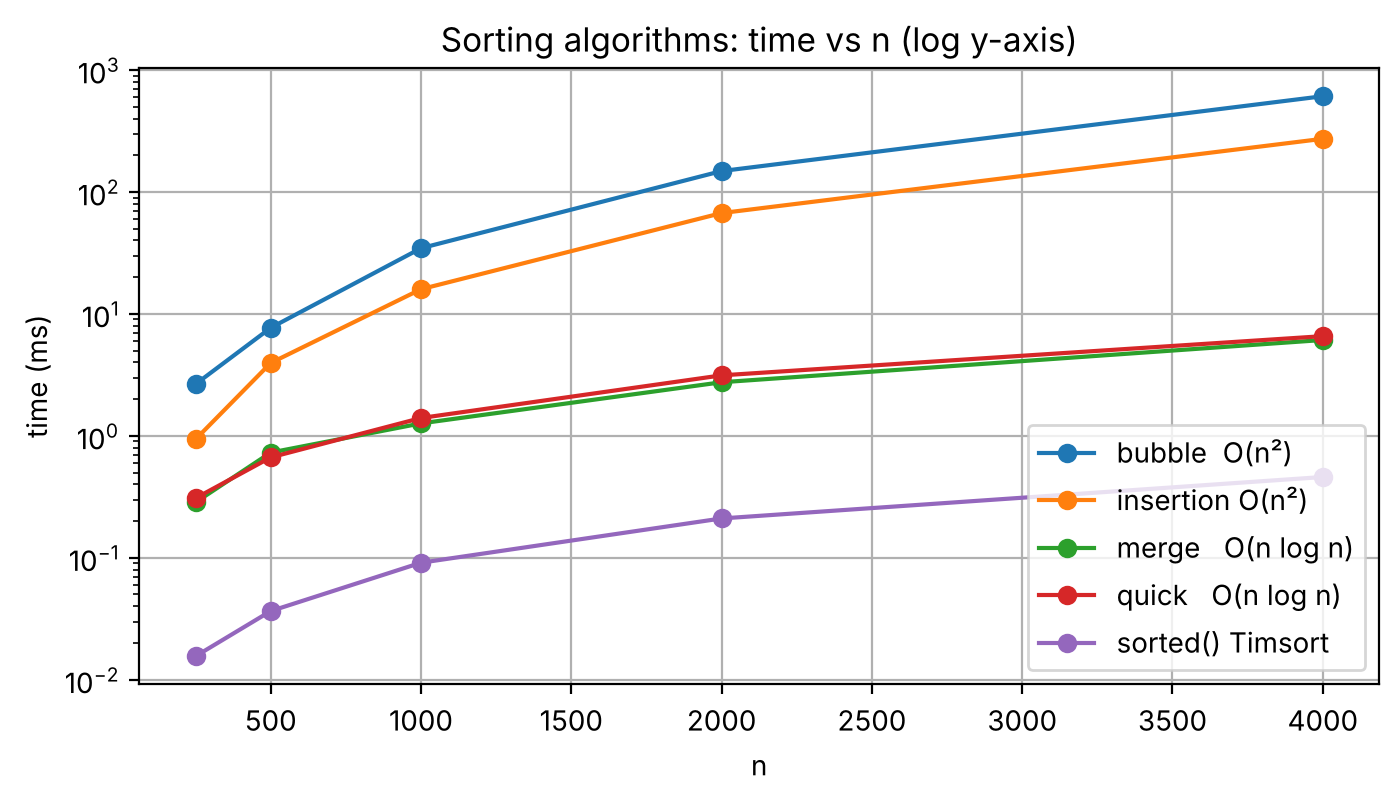

     n   bubble  O   insertion   merge   O   quick   O   sorted() 
   250      2.65ms      0.94ms      0.28ms      0.31ms      0.02ms
   500      7.69ms      3.96ms      0.73ms      0.67ms      0.04ms
  1000     34.56ms     15.94ms      1.27ms      1.40ms      0.09ms
  2000    148.36ms     67.10ms      2.75ms      3.13ms      0.21ms
  4000    609.49ms    272.72ms      6.11ms      6.57ms      0.46ms


In [32]:
# The sorting functions to compare, by name.
sort_algos = {
    "bubble  O(n²)":      bubble_sort,
    "insertion O(n²)":    insertion_sort,
    "merge   O(n log n)": merge_sort,
    "quick   O(n log n)": quick_sort,
    "sorted() Timsort":   sorted,
}
# Input sizes, doubling each time.
sizes = [250, 500, 1000, 2000, 4000]
# One empty list of times per algorithm.
timings = {name: [] for name in sort_algos}

# For each size ...
for n in sizes:
    # ... make random floats ...
    sample = [random.random() for _ in range(n)]
    # ... and time every algorithm on the same input.
    for name, fn in sort_algos.items():
        # Best of 2 runs.
        _, t = timeit_fn(fn, sample, repeat=2)
        # Store the time.
        timings[name].append(t)

# New figure.
plt.figure()
# One line per algorithm.
for name, ts in timings.items():
    # Time in ms against n.
    plt.plot(sizes, [t * 1000 for t in ts], marker="o", label=name)
# Axis labels; log y-axis because the times span several orders of magnitude.
plt.xlabel("n"); plt.ylabel("time (ms)"); plt.yscale("log")
# Title.
plt.title("Sorting algorithms: time vs n (log y-axis)")
# Legend, then display.
plt.legend(); plt.show()

# Table header (the * unpacks the list into separate print arguments).
print(f"{'n':>6}", *[f"{name[:9]:>11}" for name in sort_algos])
# One row per input size.
for i, n in enumerate(sizes):
    # The time of every algorithm at this size.
    print(f"{n:>6}", *[f"{timings[name][i]*1000:>9.2f}ms" for name in sort_algos])

> **What to point out on the plot:** the two $O(n^2)$ curves rise with a steeper slope than the $O(n \log n)$ curves. Doubling $n$ roughly ×4 the quadratic times but only ×2.2 the linearithmic ones. Timsort sits far below everything because it's C code — same shape, smaller constant.

## 9. Percentiles, quartiles and the IQR — selecting many order statistics

A percentile is just another order statistic, so we have the same two options as for the median:

* **Sort once** ($O(n \log n)$), then every percentile is an $O(1)$ index lookup. Best when you need *many* percentiles.
* **Quickselect** ($O(n)$ each). Best when you need *one or two*.

Break-even: $k$ percentiles cost $O(n \log n)$ sorted vs $O(k \cdot n)$ selected, so sorting wins once $k > \log n$ — for a million elements, that's about 20 percentiles.

In [33]:
# Define a percentile computed from already sorted data.
def percentile_sorted(sorted_data, p):
    '''Nearest-rank with linear interpolation (matches numpy's default 'linear' method).'''
    # Number of values.
    n = len(sorted_data)
    # Fractional position of the p-th percentile in the sorted list.
    pos = (p / 100) * (n - 1)
    # The indices just below and above that position.
    lo = math.floor(pos); hi = math.ceil(pos)
    # How far between them.
    frac = pos - lo
    # Linear interpolation between the two neighbours.
    return sorted_data[lo] + frac * (sorted_data[hi] - sorted_data[lo])

# Sort once.
s_small = sorted(small)
# Three percentiles from the same sorted list.
q1, q2, q3 = (percentile_sorted(s_small, p) for p in (25, 50, 75))
# Interquartile range.
iqr = q3 - q1
# Print the quartiles and the IQR.
print(f"Q1={q1}, median={q2}, Q3={q3}, IQR={iqr}")
# NumPy's percentile gives the same values.
print("numpy agrees:", np.percentile(small, [25, 50, 75]))

# Tukey's fence: values beyond 1.5·IQR from the quartiles are outliers
lo_fence, hi_fence = q1 - 1.5 * iqr, q3 + 1.5 * iqr
outliers = [x for x in small if x < lo_fence or x > hi_fence]    # O(n) scan
# Print the fences and the outliers.
print(f"fences = [{lo_fence}, {hi_fence}] → outliers: {outliers}")

Q1=7.0, median=9.0, Q3=13.0, IQR=6.0
numpy agrees: [ 7.  9. 13.]
fences = [-2.0, 22.0] → outliers: [25, 96]


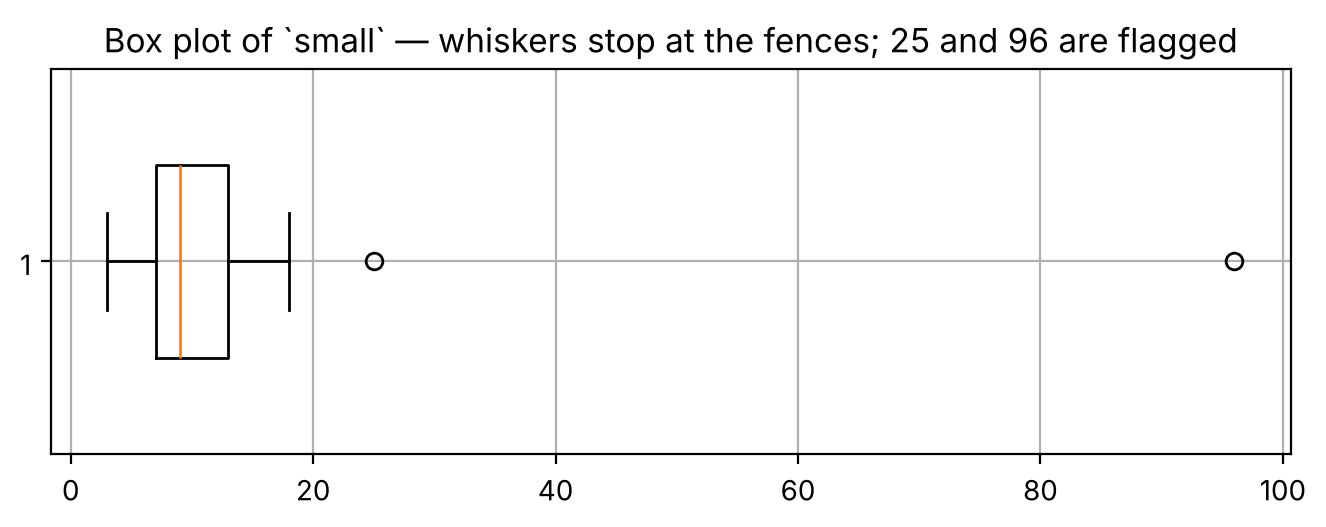

In [34]:
# A wide, short figure.
plt.figure(figsize=(8, 2.5))
# Horizontal box plot.
plt.boxplot(small, vert=False, widths=0.5)
# Title.
plt.title("Box plot of `small` — whiskers stop at the fences; 25 and 96 are flagged")
# Display.
plt.show()

## 10. Histogram / frequency distribution — $O(n + k)$

With $k$ equal-width bins, finding the bin for a value is one arithmetic expression, $O(1)$. So building a histogram is $O(n)$ for the data plus $O(k)$ to initialise and output the bins.

Contrast with a histogram over *arbitrary* bin edges: finding the right bin then needs binary search, $O(\log k)$ per element → $O(n \log k)$. NumPy's `np.histogram` does exactly this switch depending on whether the bins are uniform.

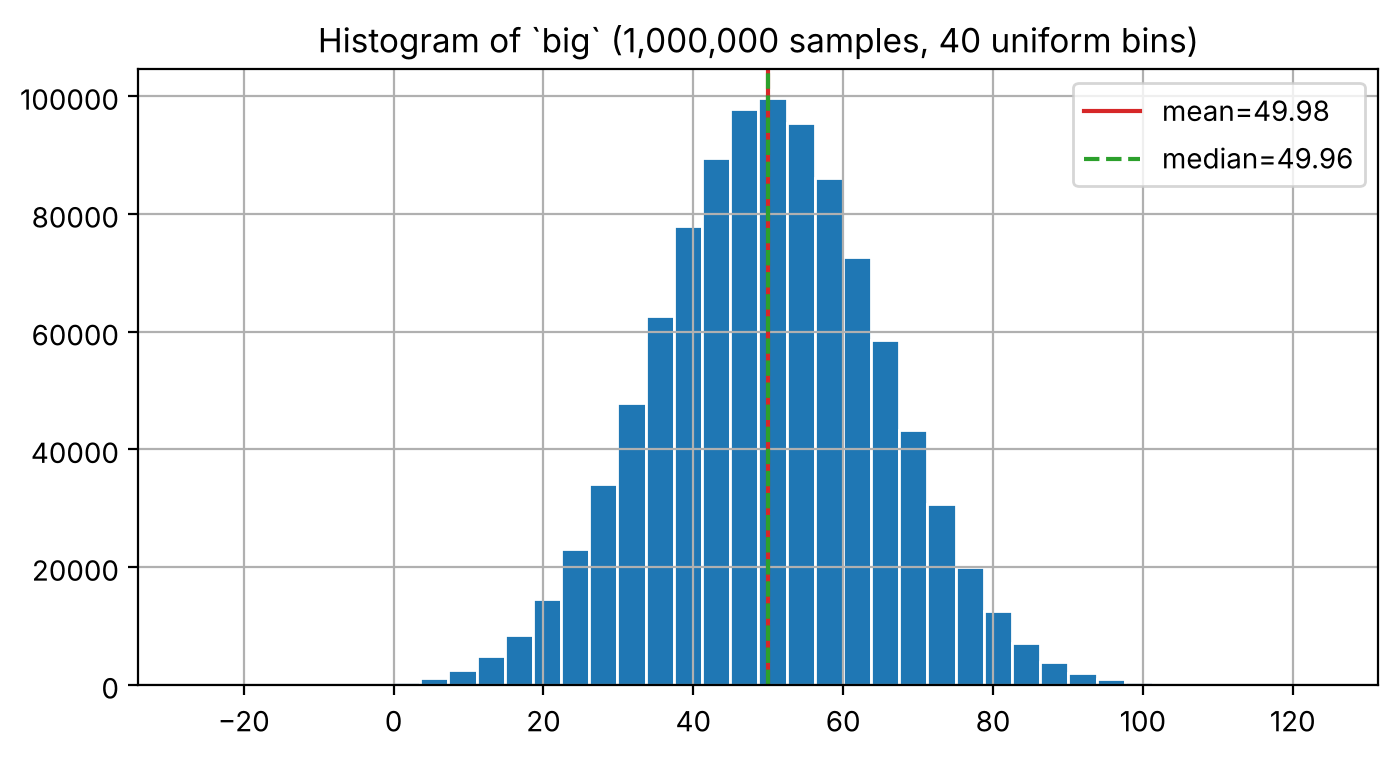

In [35]:
# Define a histogram with k equal-width bins.
def histogram_uniform(data, k, lo=None, hi=None):
    lo = min(data) if lo is None else lo          # O(n)
    hi = max(data) if hi is None else hi          # O(n)
    # Width of each bin.
    width = (hi - lo) / k
    counts = [0] * k                              # O(k)
    for x in data:                                # O(n), O(1) per element
        # Which bin x falls into.
        idx = int((x - lo) / width)
        if idx == k:                              # x == hi lands on the last bin
            # Put the maximum value in the last bin.
            idx = k - 1
        # Count it.
        counts[idx] += 1
    # The k + 1 bin edges.
    edges = [lo + i * width for i in range(k + 1)]
    # Return the counts and the edges.
    return counts, edges

# Our histogram of the big data.
counts, edges = histogram_uniform(big, k=40)
# NumPy's histogram with the same bins.
np_counts, np_edges = np.histogram(big_np, bins=40)
# They must agree exactly.
assert counts == np_counts.tolist(), "our histogram should match numpy's"

# New figure.
plt.figure()
# Draw the bars from the left edge of each bin.
plt.bar(edges[:-1], counts, width=edges[1] - edges[0], align="edge", edgecolor="white")
# Line at the mean.
plt.axvline(np.mean(big_np), color="C3", label=f"mean={np.mean(big_np):.2f}")
# Dashed line at the median.
plt.axvline(np.median(big_np), color="C2", ls="--", label=f"median={np.median(big_np):.2f}")
# Title.
plt.title("Histogram of `big` (1,000,000 samples, 40 uniform bins)")
# Legend, then display.
plt.legend(); plt.show()

## 11. Measuring complexity empirically — fitting the slope

We claimed `mean_loop` is $O(n)$, `median_sort` is $O(n \log n)$ and `mode_naive` is $O(n^2)$. Let's **verify** this experimentally.

Method: time each function at geometrically spaced $n$, plot on log–log axes, and fit a straight line. The slope estimates the exponent $k$ in $T(n) \approx c \cdot n^k$.

* $O(n)$ → slope ≈ 1
* $O(n \log n)$ → slope slightly above 1 (≈ 1.1–1.2 in this range)
* $O(n^2)$ → slope ≈ 2

mean_loop (expect ~1)        fitted exponent k ≈ 1.02


median_sort (expect ~1.1)    fitted exponent k ≈ 1.13


mode_naive (expect ~2)       fitted exponent k ≈ 2.00


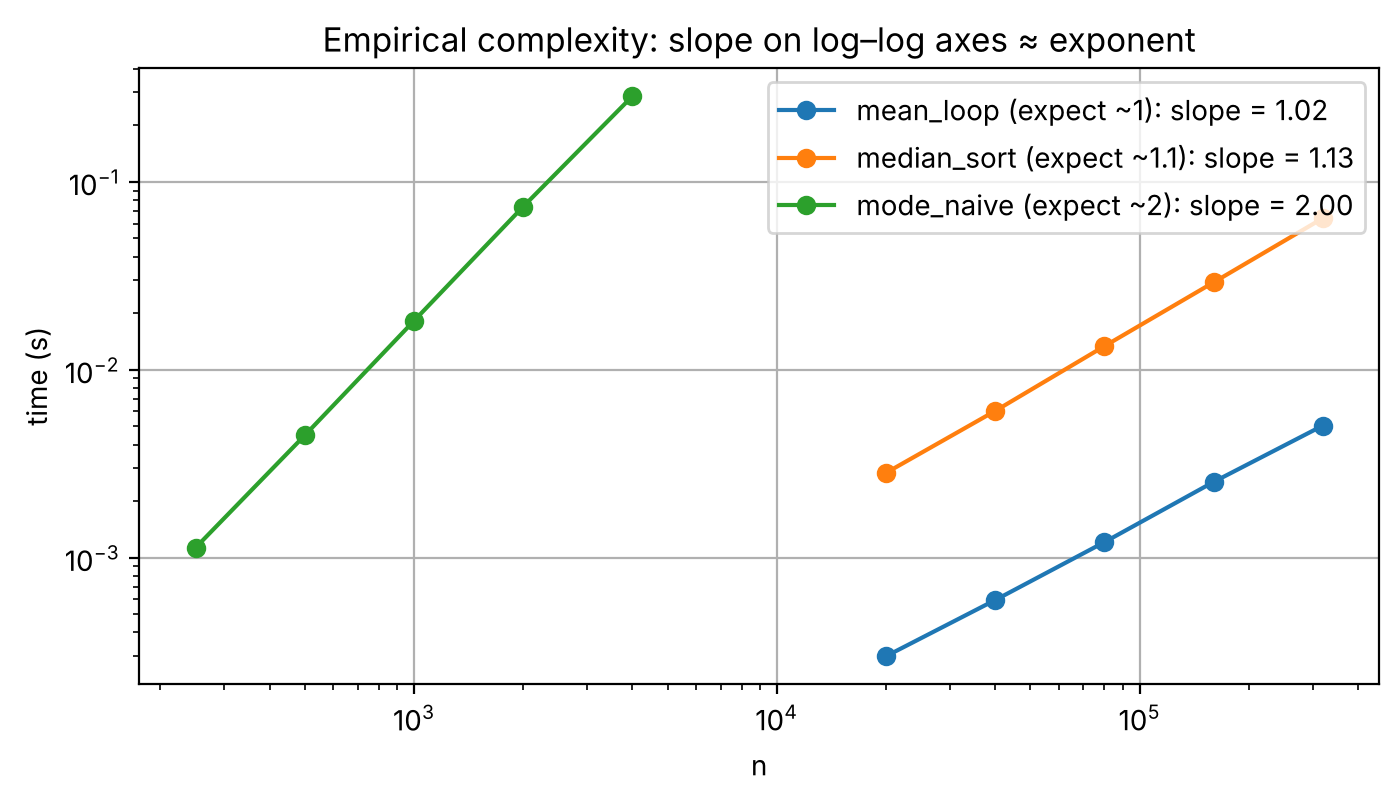

In [36]:
# Define a function that times fn at several input sizes.
def measure(fn, sizes, repeat=3):
    # The measured times.
    ts = []
    # For each size ...
    for n in sizes:
        # ... make random input ...
        sample = [random.random() for _ in range(n)]
        # ... and time the function.
        _, t = timeit_fn(fn, sample, repeat=repeat)
        # Store the time.
        ts.append(t)
    # Return the times as an array.
    return np.array(ts)

# Three algorithms, each with a range of sizes suited to its speed.
experiments = {
    "mean_loop (expect ~1)":    (mean_loop,   [20_000, 40_000, 80_000, 160_000, 320_000]),
    "median_sort (expect ~1.1)": (median_sort, [20_000, 40_000, 80_000, 160_000, 320_000]),
    "mode_naive (expect ~2)":   (mode_naive,  [250, 500, 1000, 2000, 4000]),
}

# New figure.
plt.figure()
# For each experiment ...
for label, (fn, sizes) in experiments.items():
    # ... measure the times ...
    ts = measure(fn, sizes)
    # ... and fit a straight line to log(time) vs log(n): its slope estimates k in O(n^k).
    slope, intercept = np.polyfit(np.log(sizes), np.log(ts), 1)
    # Plot the measurements on log-log axes.
    plt.loglog(sizes, ts, marker="o", label=f"{label}: slope = {slope:.2f}")
    # Print the fitted exponent.
    print(f"{label:<28} fitted exponent k ≈ {slope:.2f}")
# Axis labels.
plt.xlabel("n"); plt.ylabel("time (s)")
# Title.
plt.title("Empirical complexity: slope on log–log axes ≈ exponent")
# Legend, then display.
plt.legend(); plt.show()

> **Caveats worth discussing:** timings are noisy (other processes, CPU caches, Python's garbage collector). Slopes are estimates, not proofs. Theory tells us the *shape*; experiment confirms we implemented what we think we implemented.

## 12. Space complexity — the other axis

So far we focused on time. Let's measure memory too. `sys.getsizeof` reports the size of the container itself (not the elements it references), which is enough to see the pattern.

In [37]:
# Define a helper that formats a byte count as megabytes.
def mb(nbytes): return f"{nbytes / 1e6:.1f} MB"

print("list of 1M Python floats  :", mb(sys.getsizeof(big) + len(big) * sys.getsizeof(0.0)))   # pointers + float objects
# A NumPy array stores raw 8-byte numbers: 8 MB.
print("numpy array of 1M float64 :", mb(big_np.nbytes))
# Blank line.
print()
# Heading.
print("Extra memory used by each algorithm on the 1M list:")
# Mean and Welford keep only a few numbers.
print("  mean_loop / welford      : O(1)   — a couple of floats")
# Sorting makes a full copy of the list.
print("  median_sort              : O(n)   — the sorted copy:", mb(sys.getsizeof(sorted(big))))
# Our quickselect builds new lists.
print("  quickselect (our version): O(n)   — new lists per level; ~2n total across levels")
# The dictionary grows with the number of distinct values.
print("  mode_dict                : O(d)   — one dict entry per distinct value; here d =", len(set(ints)), "for `ints`")
# Merge sort needs temporary lists.
print("  merge_sort               : O(n)   — temporary merge buffers")
# An in-place quicksort needs only its recursion stack.
print("  in-place quicksort       : O(log n) — only the recursion stack")

list of 1M Python floats  : 32.4 MB
numpy array of 1M float64 : 8.0 MB

Extra memory used by each algorithm on the 1M list:
  mean_loop / welford      : O(1)   — a couple of floats
  median_sort              : O(n)   — the sorted copy: 8.0 MB
  quickselect (our version): O(n)   — new lists per level; ~2n total across levels
  mode_dict                : O(d)   — one dict entry per distinct value; here d = 500 for `ints`
  merge_sort               : O(n)   — temporary merge buffers
  in-place quicksort       : O(log n) — only the recursion stack


Note the **list vs. array** gap: a Python list stores a pointer to a separate 24-byte float object per element; a NumPy array stores raw 8-byte doubles contiguously. That 4× memory difference is also *why* NumPy is faster — the CPU can stream through contiguous memory.

## 13. Packaging it: a `StatAnalyzer` class

So far we have a pile of loose functions. In real code you bundle related data and operations into a **class**. A class is a blueprint; an **object** (instance) is one concrete thing built from it.

New syntax, briefly:

* `class StatAnalyzer:` — defines the blueprint.
* `def __init__(self, data):` — runs once when you create an object; `self` is the object being built.
* `self.data = data` — stores the data *inside* the object so every method can reach it.
* Methods are just functions whose first parameter is `self`.

### A design decision with a complexity cost

Several statistics (median, percentiles, min, max) want the data **sorted**. Two options:

1. Sort inside each method → every call pays $O(n \log n)$ again.
2. Sort **once** in `__init__` and keep the sorted copy → $O(n \log n)$ up front, then every order-statistic is $O(1)$. Costs $O(n)$ memory.

Option 2 is called **precomputation** (or caching). It's the right call when you'll ask many questions of the same data — which is exactly what an "analyzer" is for.

In [38]:
# Define a class that bundles the data with all its statistics.
class StatAnalyzer:
    '''Descriptive statistics for a list of numbers, with precomputed sorted copy.'''

    # The constructor runs once, when an object is created.
    def __init__(self, data):
        # Empty data?
        if len(data) == 0:
            # Stop with a clear message.
            raise ValueError("need at least one value")
        self.data = list(data)                 # O(n) copy, so outside changes can't surprise us
        # Store the number of values.
        self.n = len(self.data)
        self.sorted_data = sorted(self.data)   # O(n log n) ONCE, O(n) space

    # --- O(n) statistics -------------------------------------------------
    def mean(self):
        # Mean: sum divided by count.
        return sum(self.data) / self.n

    def variance(self, ddof=0):                # ddof=1 → sample variance
        # Reuse the stable Welford function.
        return variance_welford(self.data, ddof)

    # Standard deviation.
    def std(self, ddof=0):
        # The square root of the variance.
        return math.sqrt(self.variance(ddof))

    # All tied modes.
    def modes(self):
        # modes_all returns (modes, count); [0] takes the list of modes.
        return modes_all(self.data)[0]

    # --- O(1) statistics, thanks to the precomputed sort -----------------
    def min(self):   return self.sorted_data[0]
    # The largest value is the last one in sorted order: O(1).
    def max(self):   return self.sorted_data[-1]
    # Range = maximum - minimum.
    def range(self): return self.max() - self.min()

    # Any percentile from the stored sorted copy.
    def percentile(self, p):
        # Reuse the earlier percentile function.
        return percentile_sorted(self.sorted_data, p)

    # The median is the 50th percentile.
    def median(self):
        # Reuse percentile().
        return self.percentile(50)

    # Interquartile range.
    def iqr(self):
        # Q3 - Q1.
        return self.percentile(75) - self.percentile(25)

    def outliers(self, k=1.5):                 # O(n) scan with Tukey's fences
        # Quartiles.
        q1, q3 = self.percentile(25), self.percentile(75)
        # Tukey's fences.
        lo, hi = q1 - k * (q3 - q1), q3 + k * (q3 - q1)
        # Values outside the fences.
        return [x for x in self.data if x < lo or x > hi]

    # --- a one-shot report ----------------------------------------------
    def describe(self, name="data"):
        # Header line with the name and n.
        print(f"── {name} (n = {self.n}) ──")
        # Mean.
        print(f"  mean     = {self.mean():.3f}")
        # Median.
        print(f"  median   = {self.median():.3f}")
        # Mode(s).
        print(f"  mode(s)  = {self.modes()}")
        # Standard deviation and variance.
        print(f"  std      = {self.std():.3f}   (variance = {self.variance():.3f})")
        # Minimum, maximum and range.
        print(f"  min/max  = {self.min()} / {self.max()}   (range = {self.range():.3f})")
        # Quartiles and IQR.
        print(f"  Q1/Q3    = {self.percentile(25):.3f} / {self.percentile(75):.3f}   (IQR = {self.iqr():.3f})")
        # Outliers.
        print(f"  outliers = {self.outliers()}")

# Create an analyser for the small dataset and print its report.
StatAnalyzer(small).describe("small")
# Blank line.
print()
# The same for the scores.
StatAnalyzer(scores).describe("scores")

── small (n = 15) ──
  mean     = 15.600
  median   = 9.000
  mode(s)  = [7]
  std      = 22.205   (variance = 493.040)
  min/max  = 3 / 96   (range = 93.000)
  Q1/Q3    = 7.000 / 13.000   (IQR = 6.000)
  outliers = [25, 96]

── scores (n = 8) ──
  mean     = 17.000
  median   = 15.000
  mode(s)  = [12]
  std      = 5.895   (variance = 34.750)
  min/max  = 12 / 30   (range = 18.000)
  Q1/Q3    = 12.000 / 19.000   (IQR = 7.000)
  outliers = [30]


> ✅ **Checkpoint 13.** If a user creates `StatAnalyzer(big)` and calls `.median()` 1,000 times, what is the total cost? What if instead they call `median_quickselect(big)` 1,000 times? Which design wins, and at what number of calls does it start winning?

> 🧪 **Try it:** add a method `zscore(x)` returning $(x - \bar{x}) / \sigma$. What is its complexity if you compute the mean and std inside it every call? How would you make it $O(1)$?

## 14. Mini project: from raw readings to a conclusion

Let's apply everything to a small but realistic engineering scenario.

**Scenario.** A lab tested the tensile strength (in MPa) of steel samples from two suppliers, **A** and **B**, 60 samples each. The data logger occasionally failed, leaving gaps recorded as `None`. Your job:

1. **Clean** the data (handle missing values).
2. **Describe** each supplier with the statistics from this notebook.
3. **Compare** them: is one supplier stronger? more consistent?
4. **Flag** suspicious samples.
5. **Check** whether a second measurement (hardness) predicts strength.

We generate the data in-notebook so the project is fully self-contained.

In [39]:
# A new seed for this section, so its results do not depend on earlier cells.
random.seed(7)

# Define a function that simulates one supplier's strength readings.
def simulate_supplier(mean_mpa, sd_mpa, n=60, missing_rate=0.05):
    '''Simulate strength readings with occasional logger failures (None).'''
    # The readings.
    out = []
    # n readings.
    for _ in range(n):
        # With probability missing_rate the logger fails ...
        if random.random() < missing_rate:
            # ... and records None.
            out.append(None)
        # Otherwise ...
        else:
            # ... record a normally distributed strength, rounded to 0.1 MPa.
            out.append(round(random.gauss(mean_mpa, sd_mpa), 1))
    # Return the readings.
    return out

# Supplier A: mean 520 MPa, standard deviation 12 MPa.
strength_A = simulate_supplier(mean_mpa=520, sd_mpa=12)
# Supplier B: slightly higher mean, twice the spread.
strength_B = simulate_supplier(mean_mpa=528, sd_mpa=25)
strength_B[17] = 611.4      # a suspicious reading — typo? mislabelled sample?

# First 12 readings of A.
print("A:", strength_A[:12], "...")
# First 12 readings of B.
print("B:", strength_B[:12], "...")
# How many readings are missing.
print("missing in A:", strength_A.count(None), "| missing in B:", strength_B.count(None))

A: [530.2, 534.1, 517.2, 523.1, None, 524.7, 522.2, 526.1, 526.0, 509.3, 514.4, None] ...
B: [537.5, 478.0, 518.6, 534.9, 543.6, 535.0, 528.5, 528.2, 524.3, 532.3, 539.3, 543.3] ...
missing in A: 4 | missing in B: 2


### Step 1 — Cleaning: $O(n)$

The simplest policy is to **drop** missing readings. (Alternatives — filling with the mean or median — are called *imputation*; they're also $O(n)$ but change the statistics, so always report which policy you used.)

In [40]:
# Define a function that removes missing readings.
def drop_missing(data):
    '''Remove None values. O(n) time, O(n) space for the new list.'''
    # Keep every value that is not None.
    return [x for x in data if x is not None]

# Clean data for A.
A = drop_missing(strength_A)
# Clean data for B.
B = drop_missing(strength_B)
# How many readings were kept.
print(f"kept {len(A)} of {len(strength_A)} readings for A, {len(B)} of {len(strength_B)} for B")

kept 56 of 60 readings for A, 58 of 60 for B


### Step 2 — Describe each supplier

In [41]:
# One analyser per supplier.
sa, sb = StatAnalyzer(A), StatAnalyzer(B)
# Report for A.
sa.describe("Supplier A")
# Blank line.
print()
# Report for B.
sb.describe("Supplier B")

── Supplier A (n = 56) ──
  mean     = 518.966
  median   = 519.300
  mode(s)  = [517.2, 523.1]
  std      = 10.594   (variance = 112.223)
  min/max  = 492.9 / 539.3   (range = 46.400)
  Q1/Q3    = 510.775 / 526.525   (IQR = 15.750)
  outliers = []

── Supplier B (n = 58) ──
  mean     = 531.386
  median   = 529.750
  mode(s)  = [529.1, 533.9]
  std      = 25.514   (variance = 650.984)
  min/max  = 469.4 / 611.4   (range = 142.000)
  Q1/Q3    = 517.600 / 539.275   (IQR = 21.675)
  outliers = [478.0, 611.4, 577.4, 576.7, 469.4, 590.1, 594.2]


### Step 3 — Compare: a picture is worth a thousand numbers

Side-by-side box plots show **centre** (median line), **spread** (box = IQR), and **outliers** (dots) in one glance.

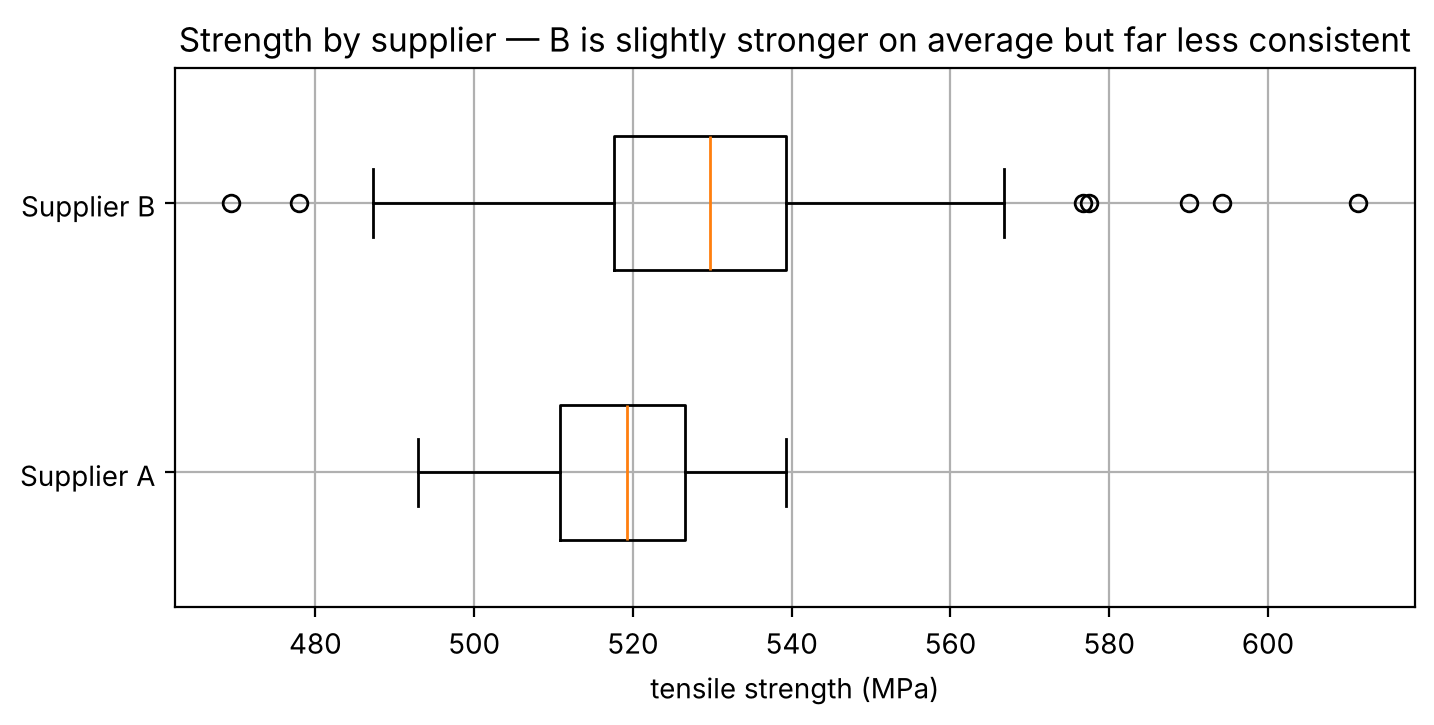

In [42]:
# A wide figure.
plt.figure(figsize=(8, 3.5))
# Two horizontal box plots, one per supplier.
plt.boxplot([A, B], vert=False, widths=0.5)
# Name the two boxes.
plt.yticks([1, 2], ["Supplier A", "Supplier B"])
# x-axis label with units.
plt.xlabel("tensile strength (MPa)")
# Title.
plt.title("Strength by supplier — B is slightly stronger on average but far less consistent")
# Display.
plt.show()

> ✅ **Checkpoint 14a.** Supplier B has the higher mean. Would you choose B for a safety-critical part? What statistic drives your answer?

### Step 4 — Flag suspicious samples with z-scores

A **z-score** says how many standard deviations a value is from the mean: $z = (x - \bar{x}) / \sigma$. For roughly bell-shaped data, $|z| > 3$ is rare (about 0.3%) — a good first filter for "check this one". Computing all z-scores is $O(n)$.

In [43]:
# Define z-scores: how many standard deviations each value is from the mean.
def zscores(data):
    mu = sum(data) / len(data)                     # O(n)
    sd = math.sqrt(variance_welford(data))         # O(n)
    return [(x - mu) / sd for x in data]           # O(n)

# For each supplier ...
for name, data in [("A", A), ("B", B)]:
    # ... compute the z-scores ...
    z = zscores(data)
    # ... and keep (value, z) pairs with |z| > 3.
    flagged = [(round(x, 1), round(zz, 2)) for x, zz in zip(data, z) if abs(zz) > 3]
    # Print the flagged readings.
    print(f"Supplier {name}: samples with |z| > 3 → {flagged}")

# Compare with Tukey's fences.
print("\nTukey fences (from StatAnalyzer) flag:", "A:", sa.outliers(), "| B:", sb.outliers())

Supplier A: samples with |z| > 3 → []
Supplier B: samples with |z| > 3 → [(611.4, 3.14)]

Tukey fences (from StatAnalyzer) flag: A: [] | B: [478.0, 611.4, 577.4, 576.7, 469.4, 590.1, 594.2]


Two methods, two answers — the IQR method flags more. Neither is "right"; they encode different assumptions (z-scores assume a bell shape, Tukey's fences don't). An engineer reports the method alongside the result.

### Step 5 — Does hardness predict strength? Correlation, $O(n)$

Suppose each sample also had a hardness test (HV). The **Pearson correlation coefficient** measures how linearly related two variables are, from $-1$ (perfect inverse) through $0$ (none) to $+1$ (perfect direct):

$$r = \frac{\sum (x_i - \bar{x})(y_i - \bar{y})}{\sqrt{\sum (x_i - \bar{x})^2}\,\sqrt{\sum (y_i - \bar{y})^2}}$$

Three sums over $n$ pairs → $O(n)$ time, $O(1)$ extra space.

r(hardness, strength) for supplier A = 0.704
numpy agrees: 0.704


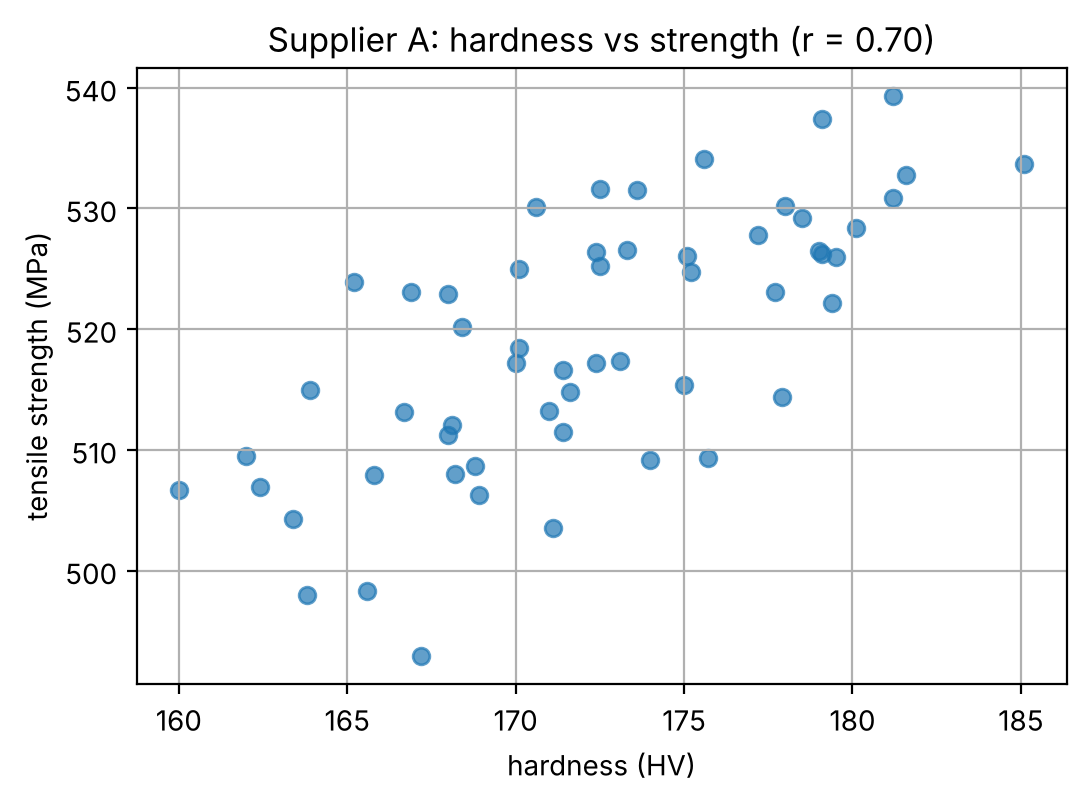

In [44]:
# Simulate hardness as strength/3 plus noise (so the relationship is real but imperfect)
hardness_A = [round(x / 3 + random.gauss(0, 4), 1) for x in A]

# Define Pearson's correlation coefficient.
def pearson_r(x, y):
    # Number of pairs.
    n = len(x)
    # Both means.
    mx, my = sum(x) / n, sum(y) / n
    # Sum of products of deviations.
    sxy = sum((a - mx) * (b - my) for a, b in zip(x, y))
    # Sum of squared x-deviations.
    sxx = sum((a - mx) ** 2 for a in x)
    # Sum of squared y-deviations.
    syy = sum((b - my) ** 2 for b in y)
    # r lies between -1 and +1.
    return sxy / math.sqrt(sxx * syy)

# Correlation between hardness and strength.
r = pearson_r(hardness_A, A)
# Print it.
print(f"r(hardness, strength) for supplier A = {r:.3f}")
# NumPy agrees.
print("numpy agrees:", round(float(np.corrcoef(hardness_A, A)[0, 1]), 3))

# New figure.
plt.figure(figsize=(6, 4))
# Scatter plot; alpha makes overlapping points visible.
plt.scatter(hardness_A, A, alpha=0.7)
# Axis labels with units.
plt.xlabel("hardness (HV)"); plt.ylabel("tensile strength (MPa)")
# Title showing r.
plt.title(f"Supplier A: hardness vs strength (r = {r:.2f})")
# Display.
plt.show()

### Step 6 — Write the conclusion

A data analysis isn't finished until it's a sentence someone can act on. For example:

> *After dropping the failed readings (4 for A, 2 for B), Supplier B's mean strength (≈531 MPa) exceeds A's (≈519 MPa), but B's standard deviation is roughly twice A's and B produced one reading (611 MPa) more than 3σ above its mean, which should be re-tested. For applications where consistency matters, A is the safer choice. Hardness correlates with strength (r ≈ 0.7) and could serve as a cheap screening test.*

> 🧪 **Try it:** change `sd_mpa` for supplier B to 12 (same as A) and re-run Steps 1–6. Does the conclusion change? Then change `missing_rate` to 0.3 — what breaks first?

> ✅ **Checkpoint 14b.** List the complexity of *each* step of this project. Which single step dominates the total running time, and would that change if $n$ were 10 million?

## 15. Summary

| Statistic | Best algorithm | Time | Extra space | Notes |
|---|---|---|---|---|
| Mean | single pass | $O(n)$ | $O(1)$ | optimal; streamable |
| Variance / std | Welford | $O(n)$ | $O(1)$ | one pass **and** stable |
| Min / max | pairwise | $O(n)$ | $O(1)$ | $1.5n$ comparisons |
| Median | quickselect / introselect | $O(n)$ avg | $O(1)$–$O(n)$ | sort is $O(n\log n)$ but fine in practice |
| Mode | hash-map counting | $O(n)$ avg | $O(d)$ | sort+scan is $O(n \log n)$, $O(1)$ extra |
| $k$ percentiles | sort once | $O(n \log n)$ | $O(n)$ | select instead when $k < \log n$ |
| Histogram (uniform bins) | direct indexing | $O(n + k)$ | $O(k)$ | $O(n \log k)$ for arbitrary edges |
| Sorting | Timsort / merge sort | $O(n \log n)$ | $O(n)$ | comparison sorting can't beat $n \log n$ |
| Cleaning (drop `None`) | one filter pass | $O(n)$ | $O(n)$ | |
| z-scores | three passes | $O(n)$ | $O(n)$ | output is itself a list of $n$ |
| Correlation ($r$) | three sums | $O(n)$ | $O(1)$ | |

### Four take-home ideas

1. **Big-O is about scaling, not speed.** A C implementation of a worse algorithm can beat a Python implementation of a better one — up to some $n$. Beyond that $n$, asymptotics always win.
2. **Data structures change complexity classes.** Mode went $O(n^2) \to O(n \log n) \to O(n)$ purely by choosing a hash map.
3. **Same Big-O ≠ same algorithm.** Welford vs the naïve one-pass variance have identical complexity; one gives wrong answers.
4. **Precompute when you'll ask many questions.** `StatAnalyzer` sorts once ($O(n \log n)$) so every later percentile is $O(1)$ — paying memory to buy time.

## 16. Exercises

**Warm-up (Python & statistics)**

1. **Count by hand.** Write `count_ops_median_sort` in the style of `count_ops_sum` (Section 2) that returns the median *and* an operation count for the final "pick the middle" step only. Why is that step $O(1)$ no matter how big the list?
2. **Robust mean.** A *trimmed mean* drops the lowest and highest 10% of values before averaging. Implement `trimmed_mean(data, fraction=0.1)`. What is its complexity, and why is it more than $O(n)$?
3. **Imputation.** Write `fill_missing(data, strategy)` where `strategy` is `"mean"` or `"median"`, and compare the resulting supplier statistics with the drop-missing version from Section 14.

**Core (algorithms)**

4. **Lower bound.** Argue (informally) why no comparison-based sorting algorithm can run faster than $\Omega(n \log n)$ in the worst case. *(Hint: how many possible orderings of $n$ elements are there, and how many does one comparison rule out?)*
5. **Counting sort.** If the data are integers in a small range $[0, m)$, sorting can be done in $O(n + m)$ — beating the bound above. Implement it and explain why it doesn't contradict exercise 4.
6. **Worst-case quickselect.** Replace `random.choice(data)` with `data[0]` and feed `quickselect` an already-sorted list. Measure the running time for $n = 500, 1000, 2000$ and confirm the slope on a log–log plot is ≈ 2.
7. **Measure, then explain.** `mode_sorted` and `median_sort` are both $O(n \log n)$. Time them on the same data — which is faster, and by how much? Explain where the extra constant comes from.

**Challenge**

8. **Streaming median.** Design a data structure that supports `add(x)` and `median()` where each operation is $O(\log n)$. *(Hint: two heaps.)* Implement it using `heapq` and verify against `median_sort` on `small`.
9. **Weighted mean.** Extend `running_mean` to a weighted running mean. What are its time and space complexities?
10. **Your own data.** Replace the simulated supplier data in Section 14 with real measurements from a lab session (type them in or upload a CSV and read it with `csv.reader`). Produce the six-step analysis and a one-paragraph conclusion.

1. **Lower bound.** Argue (informally) why no comparison-based sorting algorithm can run faster than $\Omega(n \log n)$ in the worst case. *(Hint: how many possible orderings of $n$ elements are there, and how many does one comparison rule out?)*
2. **Counting sort.** If the data are integers in a small range $[0, m)$, sorting can be done in $O(n + m)$ — beating the bound above. Implement it and explain why it doesn't contradict exercise 1.
3. **Streaming median.** Design a data structure that supports `add(x)` and `median()` where each operation is $O(\log n)$. *(Hint: two heaps.)* Implement it using `heapq` and verify against `median_sort` on `small`.
4. **Weighted mean.** Extend `running_mean` to a weighted running mean. What are its time and space complexities?
5. **Worst-case quickselect.** Replace `random.choice(data)` with `data[0]` and feed `quickselect` an already-sorted list. Measure the running time for $n = 500, 1000, 2000$ and confirm the slope on a log–log plot is ≈ 2.
6. **Measure, then explain.** `mode_sorted` and `median_sort` are both $O(n \log n)$. Time them on the same data — which is faster, and by how much? Explain where the extra constant comes from.

In [45]:
# 🧪 Workspace for exercises — edit freely during class.

## 17. Where to go next

You now own the full chain: a list of numbers → hand-written algorithms → their complexity → a reusable class → a small analysis with a conclusion. The natural next step is the kind of statistics engineers use on the job — judging whether a process is in control, how capable it is, how long a part will last, how uncertain a measurement is.

All of that is in **engstat**, an open-source library and course written for exactly this audience:

[github.com/ktwyw/engstat](https://github.com/ktwyw/engstat)

| If you enjoyed… | …look at in `engstat` |
|---|---|
| Section 6 (variance, numerical stability) | measurement uncertainty, gauge R&R |
| Section 9 (percentiles, outliers, Tukey fences) | control charts, process capability |
| Section 11 (measuring, fitting slopes) | calibration, designed experiments |
| Section 14 (comparing suppliers) | sample-size planning, Weibull life analysis |

Start with the `notebooks/` folder — it continues in the same run-it-yourself style — and check your work against `solutions/`. The library's methods are validated against NIST reference results, so it's also a trustworthy place to compare your own implementations.

## 18. Glossary

| Term | Meaning |
|---|---|
| **Algorithm** | A precise, step-by-step recipe for computing something. |
| **Big-O, $O(\cdot)$** | An upper bound on how the number of operations grows with input size $n$, ignoring constants and smaller terms. |
| **$\Omega(\cdot)$ (big-Omega)** | A *lower* bound — the least work any algorithm for the problem must do. |
| **Time complexity** | Operations as a function of $n$. |
| **Space complexity** | *Extra* memory (beyond the input) as a function of $n$. |
| **Best / average / worst case** | Complexity on the easiest, typical, and hardest inputs of size $n$. |
| **Constant factor** | The multiplier Big-O hides; why C code beats Python code of the same Big-O. |
| **Divide and conquer** | Split the problem, solve parts recursively, combine (merge sort, quickselect). |
| **Hash map / dictionary** | Key → value table with $O(1)$ average lookup; Python's `dict`. |
| **Order statistic** | The $k$-th smallest value (min, median, percentiles are all order statistics). |
| **Selection problem** | Finding one order statistic without fully sorting. |
| **Stable sort** | Equal elements keep their original relative order (Timsort is stable). |
| **In-place** | Uses $O(1)$ extra memory by rearranging the input itself. |
| **Streaming / online algorithm** | Processes data one item at a time without storing it all (Welford, running mean). |
| **Numerical stability** | Whether floating-point rounding errors stay small; the naïve one-pass variance is *unstable*. |
| **Catastrophic cancellation** | Subtracting two nearly equal floats, wiping out significant digits. |
| **Mean / median / mode** | Centre of the data: average / middle value / most frequent value. |
| **Variance, $\sigma^2$ / standard deviation, $\sigma$** | Average squared distance from the mean / its square root (same units as the data). |
| **`ddof`** | "Delta degrees of freedom": divide by $n$ (`ddof=0`, population) or $n-1$ (`ddof=1`, sample). |
| **Percentile / quartile** | Value below which $p\%$ of the data falls; Q1, Q2, Q3 are the 25th, 50th, 75th percentiles. |
| **IQR** | Interquartile range, Q3 − Q1; a robust measure of spread. |
| **Outlier** | A value far from the rest; flagged by Tukey's fences ($1.5 \times$ IQR) or $\lvert z\rvert > 3$. |
| **z-score** | $(x - \bar{x})/\sigma$; distance from the mean in standard deviations. |
| **Pearson correlation, $r$** | Strength of a *linear* relationship between two variables, from −1 to +1. |
| **Imputation** | Filling in missing values (e.g. with the mean or median) instead of dropping them. |
| **Precomputation / caching** | Doing expensive work once up front so later queries are cheap. |